# E57 · única evaluación final de TEST

Modelo original de época14, entrenado con878 pacientes y seleccionado con219 de validación. Umbral0,325 y media de probabilidades por paciente fijados antes de abrir test. 176pacientes/1.758cortes de test público. Sin entrenamiento ni ajustes con test.

| Métrica           |   Valor | IC95          |
|:------------------|--------:|:--------------|
| ROC-AUC           |  0.5728 | 0.4753–0.6706 |
| AP                |  0.4206 | 0.3052–0.5548 |
| Sensibilidad      |  0.3396 | 0.2157–0.4630 |
| Especificidad     |  0.748  | 0.6696–0.8261 |
| Precisión pCR     |  0.3673 | 0.2321–0.5116 |
| F1 pCR            |  0.3529 | 0.2273–0.4685 |
| Balanced accuracy |  0.5438 | 0.4690–0.6196 |
| Brier             |  0.2116 | 0.1814–0.2428 |

Matriz: **TN92, FP31, FN35, TP18**.

Los intervalos son bootstrap por paciente, con2.000 remuestreos y semilla42. La validación seleccionó época y umbral; el test mide este checkpoint fijo, no la media de máximos de cinco modelos. Cualquier cambio posterior basado en test convertiría este conjunto en datos de desarrollo.

Uso educativo, sin validez clínica.


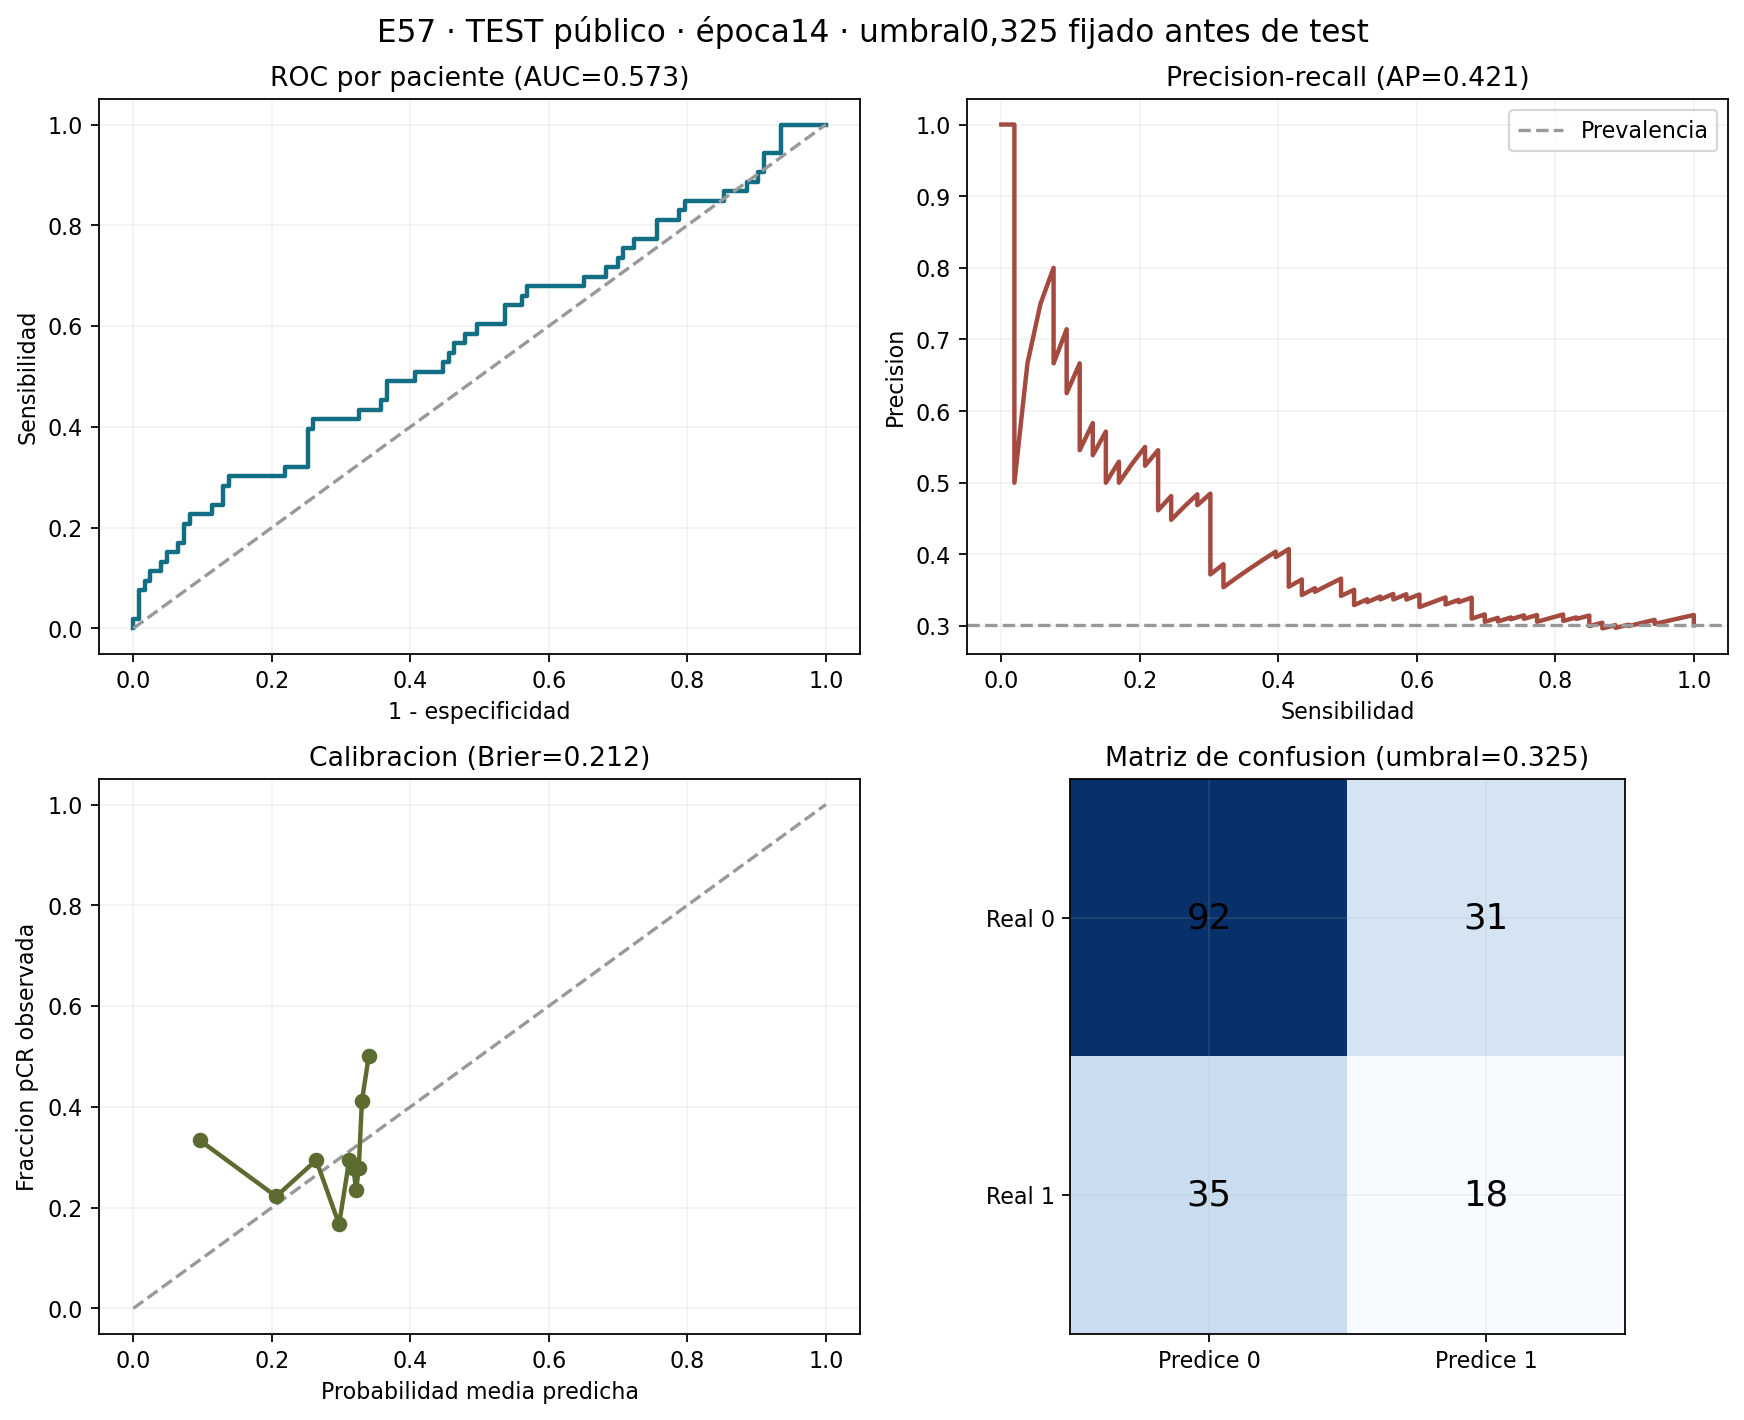

In [1]:
# E57 · resultados finales TEST
# Imagen guardada; visible sin ejecutar esta celda.


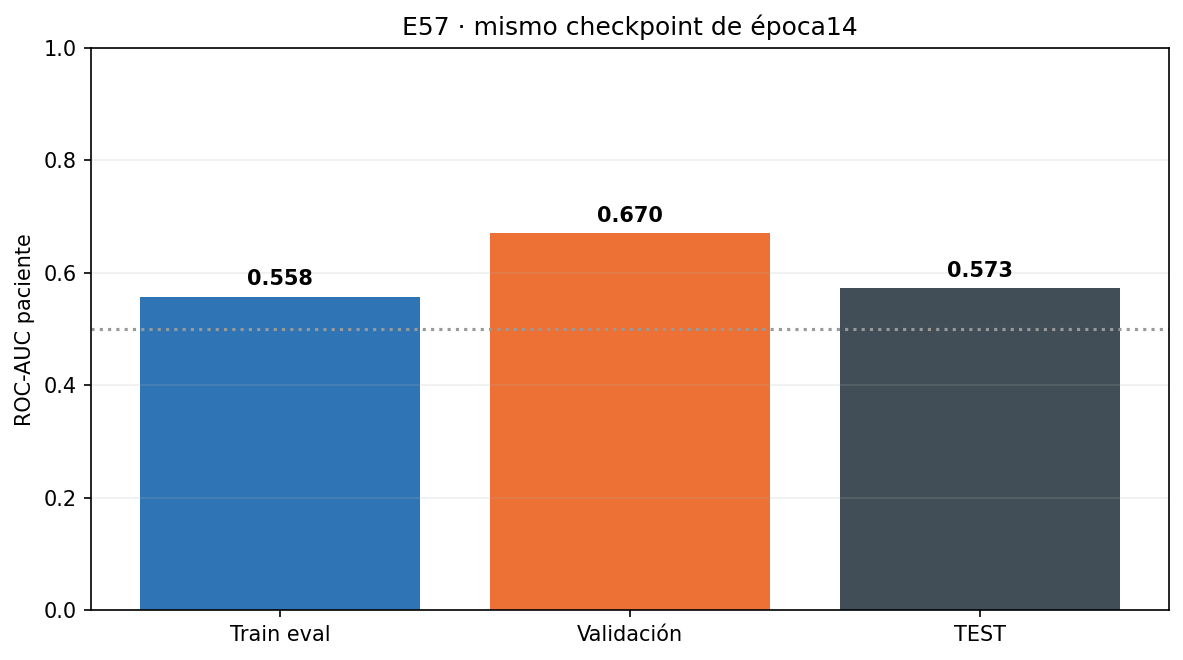

In [1]:
# E57 · train/validación/test del mismo checkpoint
# Imagen guardada; visible sin ejecutar esta celda.


# E57 · arquitectura y resultados de los cinco folds

E57 es una CNN 2D propia entrenada desde cero, con **298.161 parámetros**. Recibe PRE, EARLY y LATE y construye PRE, EARLY−PRE y LATE−EARLY. Tiene cuatro bloques de canales 16/32/64/128, dos convoluciones por bloque, BatchNorm, ReLU y cuatro reducciones MaxPool. Después usa promedio espacial global y una cabeza 128→32→1 con ReLU y dropout 0,3.

En entrenamiento se agrupan dos pacientes por lote y se promedian las características de todos sus cortes antes de la cabeza. La pérdida es una BCE normal por paciente. En la evaluación principal se predice cada corte y se promedian sus probabilidades por paciente; esta agregación es distinta de promediar características antes de la cabeza.

AdamW: LR inicial 0,001 y weight decay 0,001; ReduceLROnPlateau según AUC paciente, factor 0,5 y paciencia 3. Semilla 42, máximo 50 épocas y parada tras 10 épocas sin mejorar el AUC de validación. No se usan aumentos, pesos preentrenados, edad ni menopausia. El escalado docente de las intensidades se conserva.

Los cinco folds agrupan cortes de la misma paciente. El fold 0 es histórico y los folds 1–4 se ejecutaron después con la misma receta. La época se eligió con el AUC del mismo fold que se reporta: la media **0,6224** de los cinco máximos es descriptiva y optimista, no una evaluación exterior independiente. Un protocolo anterior con selección interna distinta obtuvo AUC exterior media 0,5272.

Las matrices de este dossier usan **umbral 0,325**, solicitado después de observar la validación. El AUC y las probabilidades no cambian por ese umbral. Los resultados se presentan como exploratorios; bajar el corte aumenta tanto las positivas detectadas como las falsas alarmas. Test ya evaluado para el checkpoint original de época 14; ver la sección final de test.

Las tres gráficas por fold reproducen el propósito de la referencia del profesor: pérdida por época, AUC por época y barras de AUC en la misma época elegida. Para el fold 0 falta la serie train-eval completa: se muestran sus pérdidas históricas con la advertencia correspondiente y un único punto train-eval auditado en la época 14. **La barra real de test solo se añade al fold 0, que es el modelo evaluado; los otros cuatro modelos no se evalúan en test.**


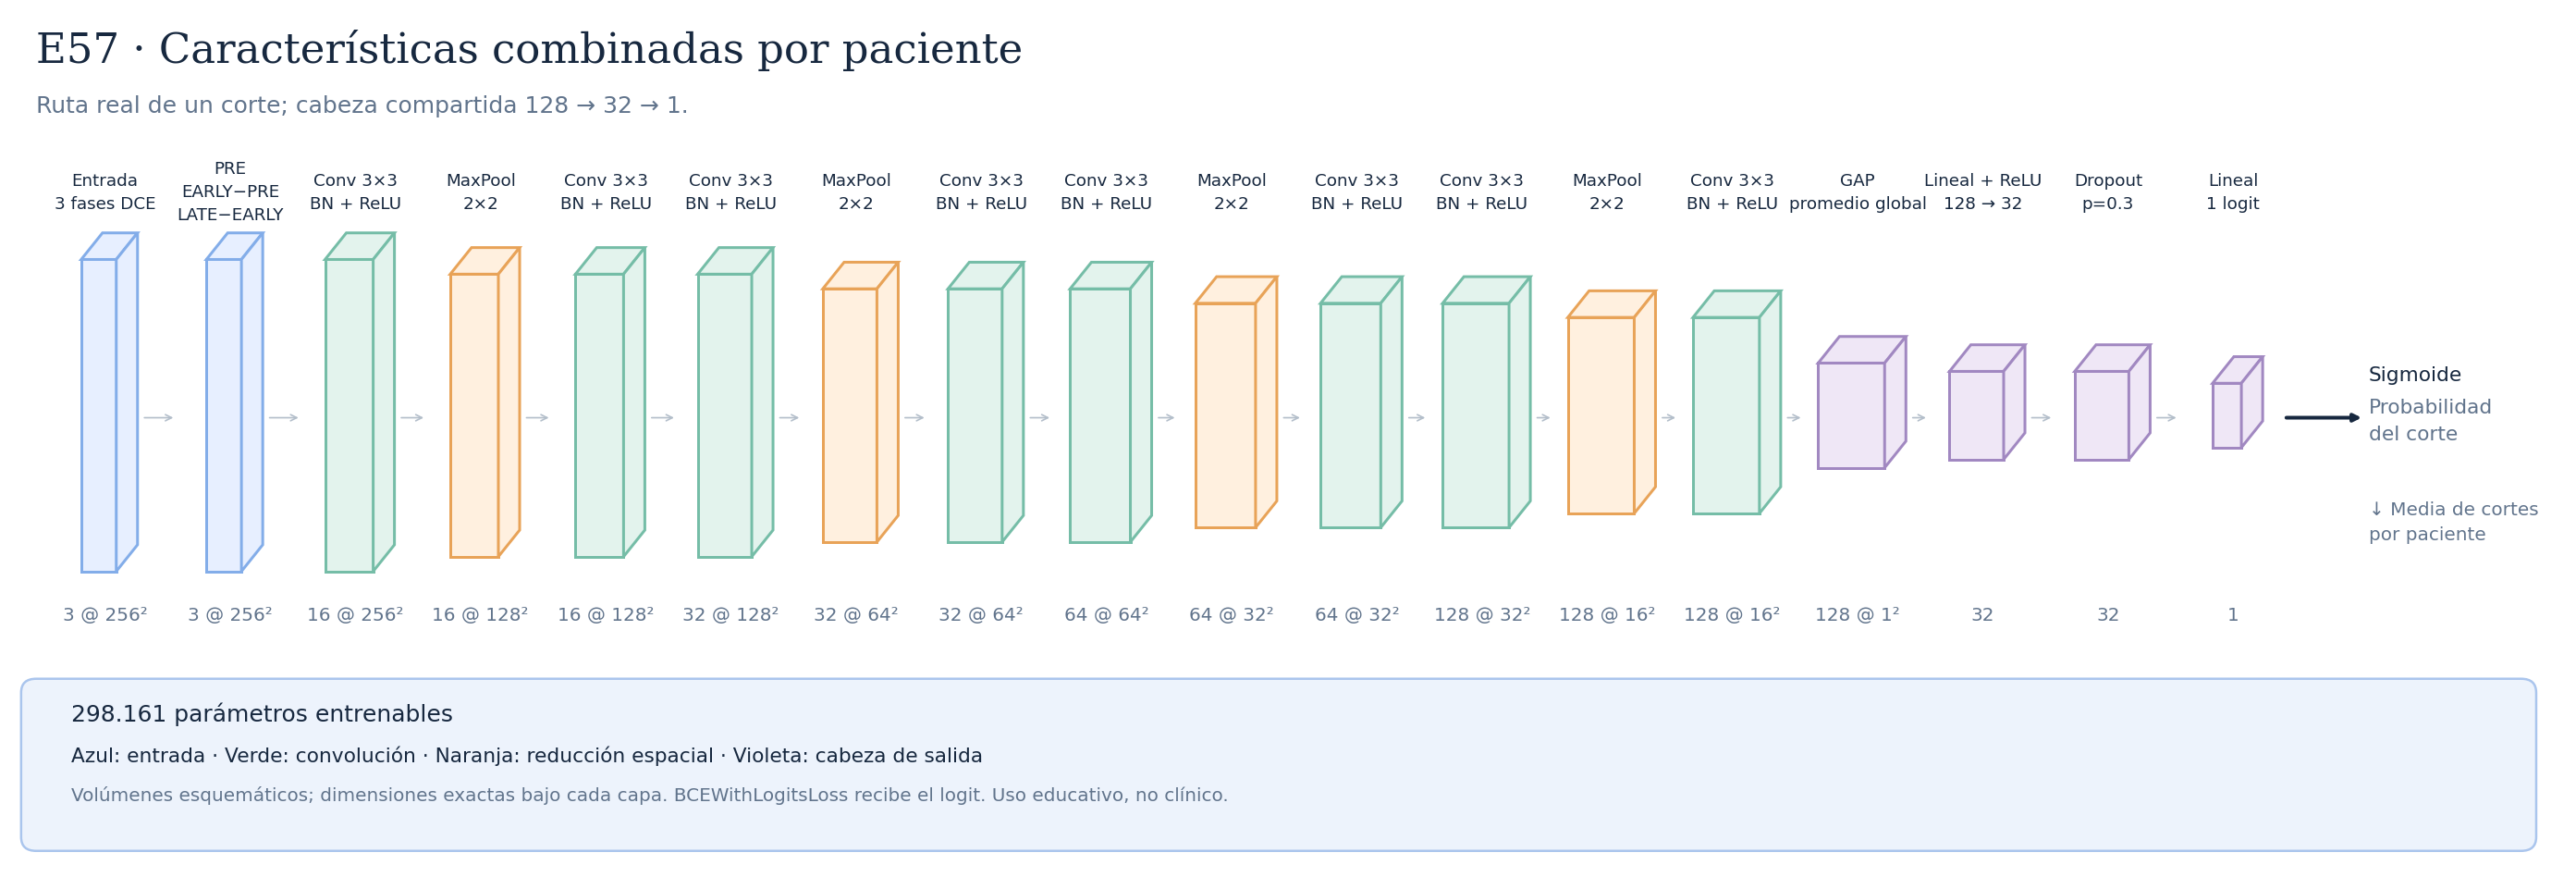

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/ARQUITECTURA.png')))

## Resumen de resultados · umbral 0,325

|   Fold |   Épocas |   Mejor época |   AUC paciente |   AP paciente |   Precisión pCR |   Sensibilidad |   Especificidad |     BA |   TN |   FP |   FN |   TP |
|-------:|---------:|--------------:|---------------:|--------------:|----------------:|---------------:|----------------:|-------:|-----:|-----:|-----:|-----:|
|      0 |       24 |            14 |         0.6703 |        0.4225 |          0.439  |         0.5625 |          0.7032 | 0.6329 |  109 |   46 |   28 |   36 |
|      1 |       37 |            27 |         0.6299 |        0.4108 |          0.338  |         0.7742 |          0.4013 | 0.5877 |   63 |   94 |   14 |   48 |
|      2 |       20 |            10 |         0.6688 |        0.4006 |          0.3272 |         0.8983 |          0.323  | 0.6106 |   52 |  109 |    6 |   53 |
|      3 |       12 |             2 |         0.5503 |        0.4161 |          0.5714 |         0.0533 |          0.9793 | 0.5163 |  142 |    3 |   71 |    4 |
|      4 |       15 |             5 |         0.5927 |        0.3977 |          0.29   |         0.9355 |          0.0955 | 0.5155 |   15 |  142 |    4 |   58 |

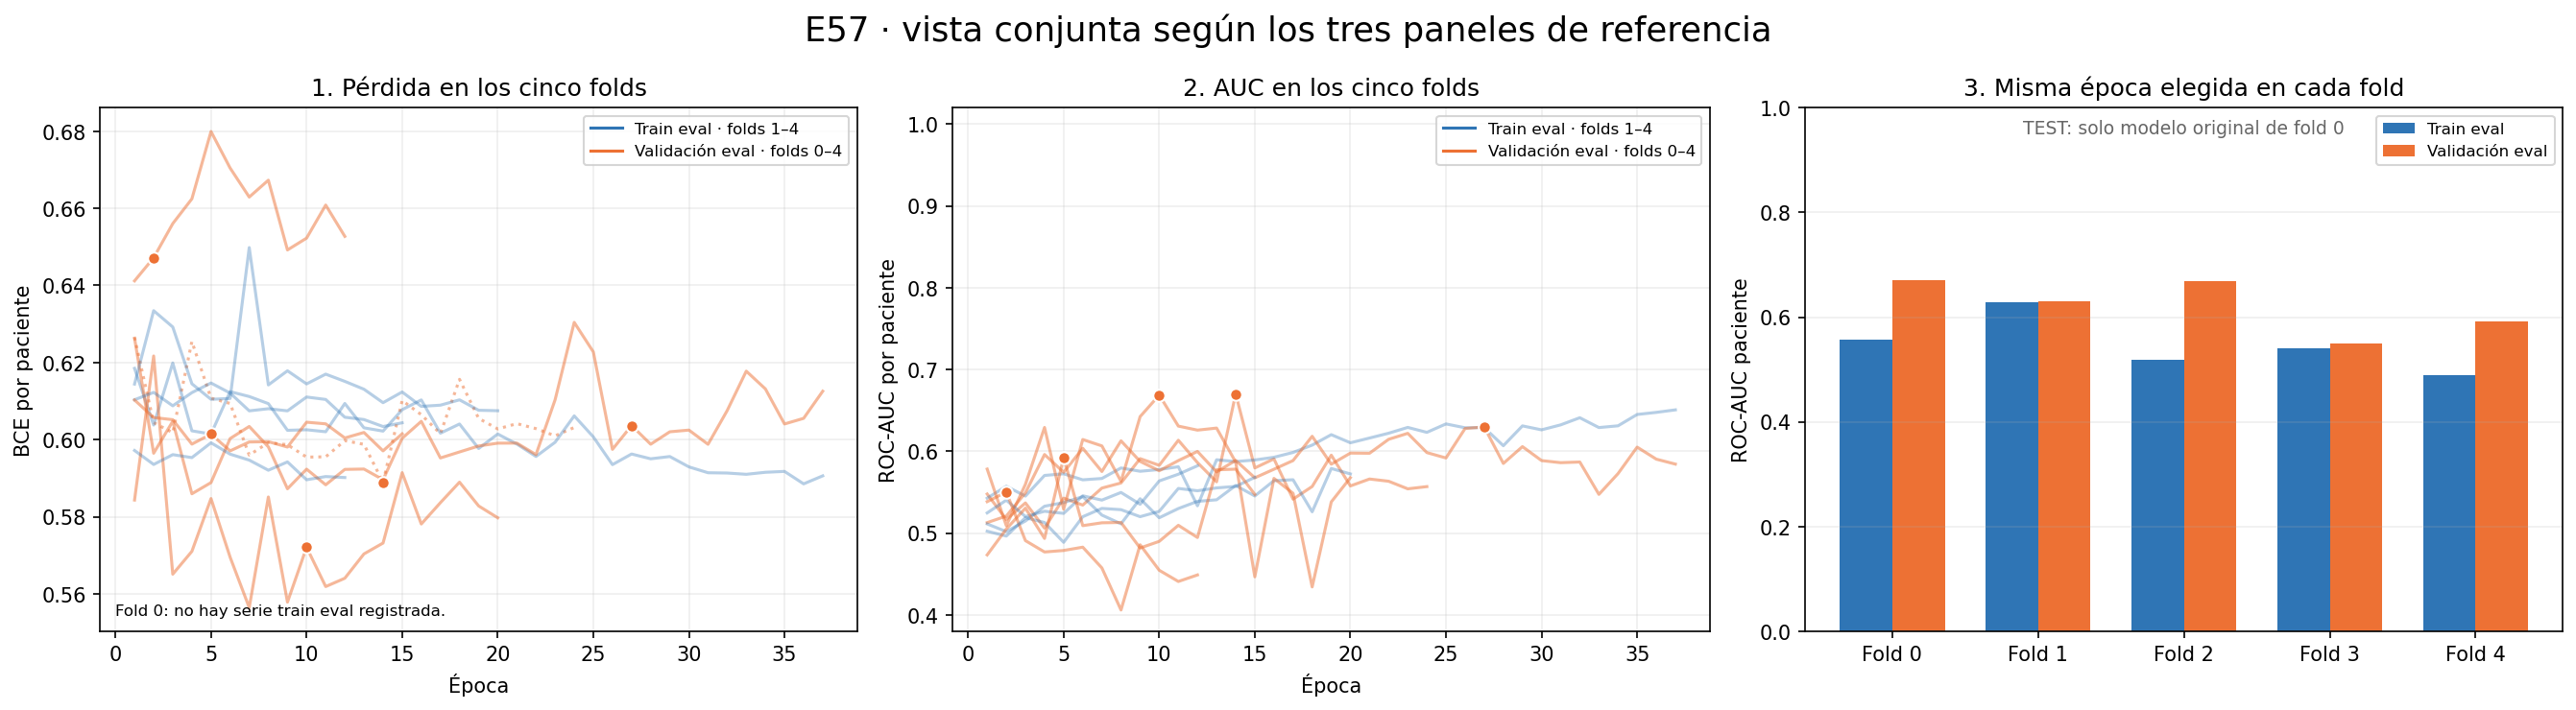

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/COMPARACION_CINCO_FOLDS.png')))

## Fold 0 · 24 épocas · checkpoint de época 14

En esta tabla, «No registrado» significa que no existe la medida train-eval por época; el único valor mostrado en la época 14 procede de la auditoría posterior.

### Todas las épocas

|   Época |   BCE train online | BCE train eval   |   BCE val eval | AUC train eval   |   AUC val |   AP val |      LR |   Segundos | Elegida   |
|--------:|-------------------:|:-----------------|---------------:|:-----------------|----------:|---------:|--------:|-----------:|:----------|
|       1 |            0.62179 | No registrado    |        0.6265  | No registrado    |   0.54788 |  0.31282 | 0.001   |    59.9603 |           |
|       2 |            0.62826 | No registrado    |        0.6044  | No registrado    |   0.51673 |  0.29005 | 0.001   |    58.3724 |           |
|       3 |            0.61886 | No registrado    |        0.6018  | No registrado    |   0.537   |  0.29671 | 0.001   |    58.8445 |           |
|       4 |            0.62324 | No registrado    |        0.62545 | No registrado    |   0.50625 |  0.31459 | 0.001   |    62.3602 |           |
|       5 |            0.61387 | No registrado    |        0.61076 | No registrado    |   0.54284 |  0.31774 | 0.001   |    67.0207 |           |
|       6 |            0.61382 | No registrado    |        0.60939 | No registrado    |   0.53438 |  0.31149 | 0.0005  |    64.2278 |           |
|       7 |            0.61162 | No registrado    |        0.59599 | No registrado    |   0.55514 |  0.31898 | 0.0005  |    63.9208 |           |
|       8 |            0.60743 | No registrado    |        0.59922 | No registrado    |   0.56139 |  0.33609 | 0.0005  |    69.5005 |           |
|       9 |            0.61149 | No registrado    |        0.59868 | No registrado    |   0.59113 |  0.38318 | 0.0005  |    65.522  |           |
|      10 |            0.61212 | No registrado    |        0.59546 | No registrado    |   0.58296 |  0.37678 | 0.0005  |    64.6509 |           |
|      11 |            0.61136 | No registrado    |        0.59554 | No registrado    |   0.61361 |  0.39064 | 0.0005  |    64.8927 |           |
|      12 |            0.61526 | No registrado    |        0.59973 | No registrado    |   0.58629 |  0.36006 | 0.0005  |    71.7339 |           |
|      13 |            0.61515 | No registrado    |        0.59877 | No registrado    |   0.5628  |  0.32653 | 0.0005  |    71.1483 |           |
|      14 |            0.614   | 0.62136          |        0.58892 | 0.55772          |   0.67026 |  0.42249 | 0.0005  |    74.7679 | Sí        |
|      15 |            0.61216 | No registrado    |        0.61016 | No registrado    |   0.57974 |  0.34207 | 0.0005  |    70.514  |           |
|      16 |            0.61376 | No registrado    |        0.60647 | No registrado    |   0.59083 |  0.35416 | 0.0005  |    67.5073 |           |
|      17 |            0.61135 | No registrado    |        0.60155 | No registrado    |   0.54163 |  0.32233 | 0.0005  |    68.6671 |           |
|      18 |            0.6039  | No registrado    |        0.61564 | No registrado    |   0.55706 |  0.31953 | 0.0005  |    66.6865 |           |
|      19 |            0.61036 | No registrado    |        0.60552 | No registrado    |   0.59536 |  0.38333 | 0.00025 |    66.6167 |           |
|      20 |            0.60635 | No registrado    |        0.60277 | No registrado    |   0.55776 |  0.34698 | 0.00025 |    66.6881 |           |
|      21 |            0.6093  | No registrado    |        0.60414 | No registrado    |   0.56623 |  0.32646 | 0.00025 |    67.6582 |           |
|      22 |            0.60486 | No registrado    |        0.60285 | No registrado    |   0.56351 |  0.32668 | 0.00025 |    67.9427 |           |
|      23 |            0.60652 | No registrado    |        0.60098 | No registrado    |   0.55423 |  0.32492 | 0.00012 |    67.5364 |           |
|      24 |            0.60379 | No registrado    |        0.60315 | No registrado    |   0.55696 |  0.31818 | 0.00012 |    67.6108 |           |

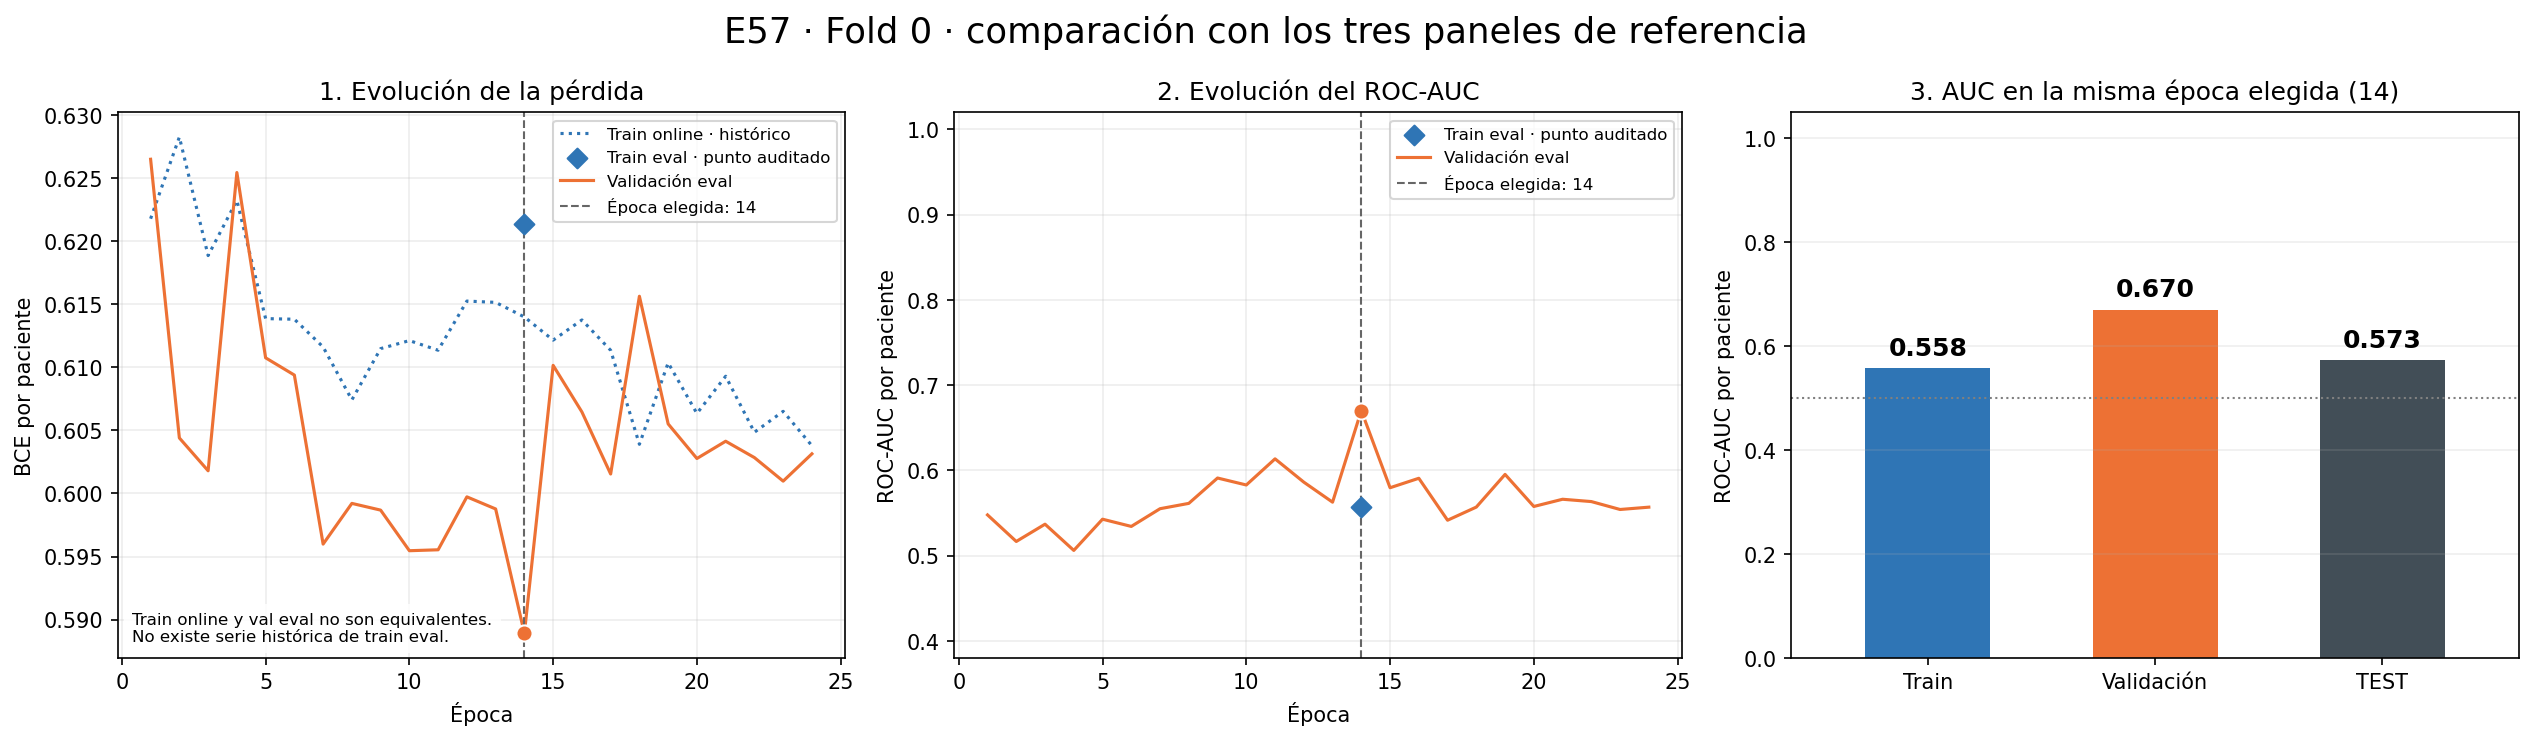

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_0_TRES_GRAFICAS.png')))

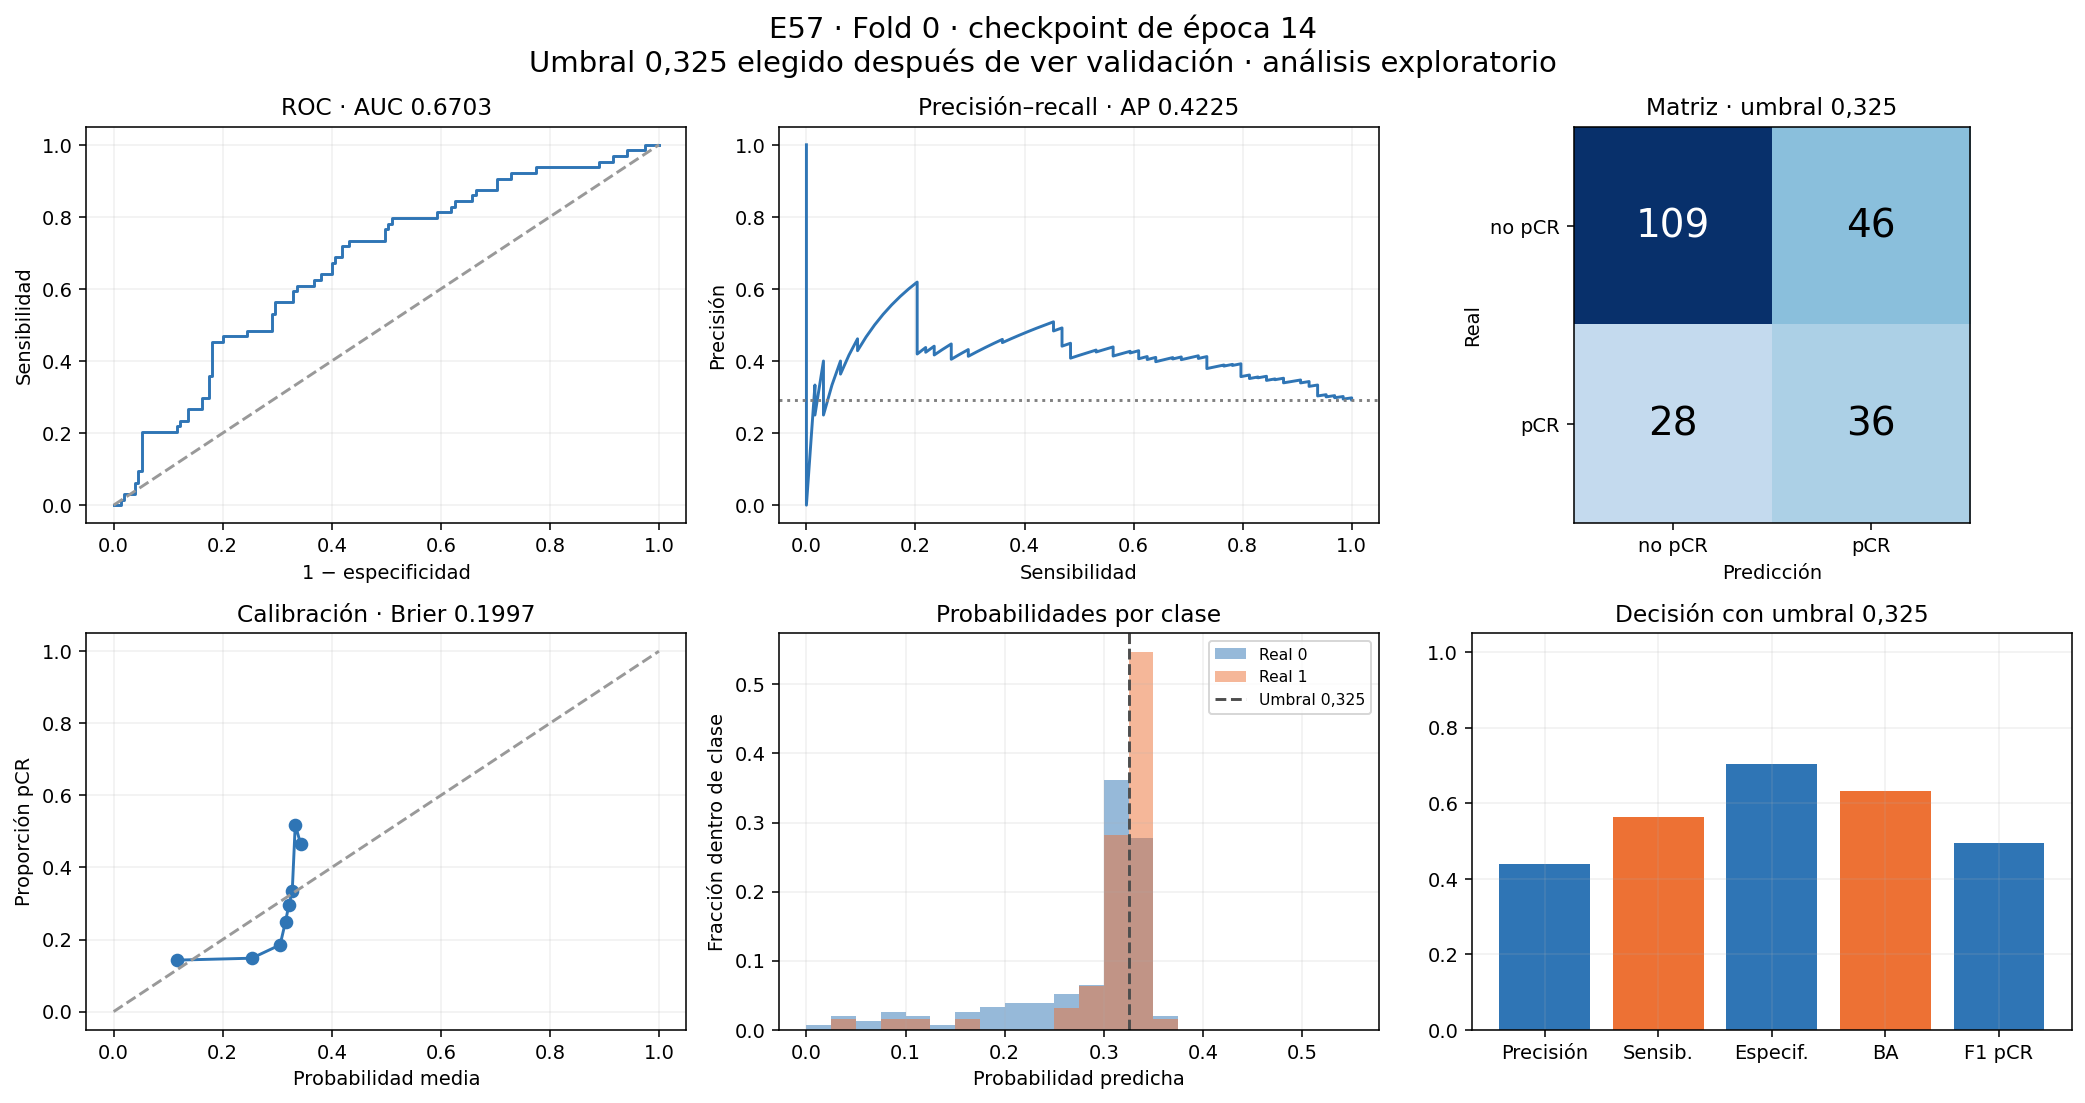

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_0_RESULTADOS.png')))

## Fold 1 · 37 épocas · checkpoint de época 27

### Todas las épocas

|   Época |   BCE train online |   BCE train eval |   BCE val eval |   AUC train eval |   AUC val |   AP val |      LR |   Segundos | Elegida   |
|--------:|-------------------:|-----------------:|---------------:|-----------------:|----------:|---------:|--------:|-----------:|:----------|
|       1 |            0.62181 |          0.61848 |        0.62632 |          0.54284 |   0.51294 |  0.32112 | 0.001   |    96.3584 |           |
|       2 |            0.62227 |          0.60379 |        0.59647 |          0.55738 |   0.52096 |  0.32798 | 0.001   |    96.3628 |           |
|       3 |            0.61727 |          0.61989 |        0.60476 |          0.54539 |   0.54931 |  0.30156 | 0.001   |    96.0331 |           |
|       4 |            0.61544 |          0.60228 |        0.58595 |          0.57059 |   0.59616 |  0.39293 | 0.001   |    95.9987 |           |
|       5 |            0.62269 |          0.60146 |        0.58885 |          0.57263 |   0.57448 |  0.36536 | 0.001   |    96.0161 |           |
|       6 |            0.60898 |          0.61245 |        0.60028 |          0.56524 |   0.60376 |  0.36064 | 0.001   |    95.6543 |           |
|       7 |            0.61389 |          0.61118 |        0.60341 |          0.56689 |   0.57541 |  0.37791 | 0.001   |    96.0824 |           |
|       8 |            0.61237 |          0.60934 |        0.59812 |          0.57972 |   0.6129  |  0.39394 | 0.001   |    95.7866 |           |
|       9 |            0.61194 |          0.60241 |        0.58724 |          0.57571 |   0.58773 |  0.39719 | 0.001   |    95.6653 |           |
|      10 |            0.61683 |          0.60256 |        0.59234 |          0.5778  |   0.57633 |  0.37402 | 0.001   |    95.8468 |           |
|      11 |            0.61019 |          0.60204 |        0.58828 |          0.58121 |   0.58876 |  0.3672  | 0.001   |    96.473  |           |
|      12 |            0.61883 |          0.60938 |        0.59228 |          0.53348 |   0.59996 |  0.35634 | 0.001   |    98.7074 |           |
|      13 |            0.60653 |          0.60306 |        0.59237 |          0.58976 |   0.57489 |  0.34144 | 0.0005  |   104.116  |           |
|      14 |            0.61529 |          0.60221 |        0.5896  |          0.58755 |   0.58897 |  0.36264 | 0.0005  |   100.552  |           |
|      15 |            0.61031 |          0.60777 |        0.60034 |          0.58948 |   0.5677  |  0.32715 | 0.0005  |    94.1147 |           |
|      16 |            0.59921 |          0.6103  |        0.60474 |          0.59279 |   0.57818 |  0.38285 | 0.0005  |    94.8273 |           |
|      17 |            0.602   |          0.60167 |        0.59524 |          0.59871 |   0.58876 |  0.39278 | 0.00025 |    94.8899 |           |
|      18 |            0.60747 |          0.60405 |        0.5968  |          0.60765 |   0.61845 |  0.4057  | 0.00025 |    95.206  |           |
|      19 |            0.60721 |          0.5977  |        0.59835 |          0.62043 |   0.58434 |  0.36679 | 0.00025 |    95.5612 |           |
|      20 |            0.60242 |          0.60145 |        0.59908 |          0.61051 |   0.5979  |  0.39019 | 0.00025 |    95.8465 |           |
|      21 |            0.60847 |          0.59885 |        0.59909 |          0.61631 |   0.5977  |  0.39421 | 0.00025 |    96.8371 |           |
|      22 |            0.60275 |          0.59563 |        0.59611 |          0.6222  |   0.61475 |  0.39596 | 0.00025 |    96.6915 |           |
|      23 |            0.60628 |          0.59932 |        0.61034 |          0.62929 |   0.62205 |  0.38542 | 0.00012 |    96.6532 |           |
|      24 |            0.60102 |          0.60615 |        0.63041 |          0.62325 |   0.59852 |  0.37435 | 0.00012 |    96.329  |           |
|      25 |            0.60073 |          0.60071 |        0.62275 |          0.63356 |   0.59195 |  0.34297 | 0.00012 |    96.6626 |           |
|      26 |            0.5987  |          0.59351 |        0.59747 |          0.62885 |   0.628   |  0.38918 | 0.00012 |    97.545  |           |
|      27 |            0.60014 |          0.59627 |        0.60365 |          0.62905 |   0.62985 |  0.41082 | 0.00012 |    96.7517 | Sí        |
|      28 |            0.60475 |          0.59502 |        0.59881 |          0.60692 |   0.58527 |  0.37375 | 0.00012 |    96.8748 |           |
|      29 |            0.60067 |          0.59561 |        0.60203 |          0.63115 |   0.60581 |  0.38275 | 0.00012 |    97.0937 |           |
|      30 |            0.60274 |          0.59293 |        0.60247 |          0.62633 |   0.58876 |  0.3731  | 0.00012 |    96.843  |           |
|      31 |            0.60751 |          0.59141 |        0.59879 |          0.6324  |   0.58619 |  0.37276 | 0.00012 |    98.1661 |           |
|      32 |            0.59798 |          0.59133 |        0.60752 |          0.64113 |   0.58701 |  0.37067 | 6e-05   |    98.8045 |           |
|      33 |            0.59474 |          0.591   |        0.61776 |          0.62911 |   0.54746 |  0.35542 | 6e-05   |    98.7147 |           |
|      34 |            0.5969  |          0.59153 |        0.61316 |          0.63124 |   0.57284 |  0.36618 | 6e-05   |    98.3417 |           |
|      35 |            0.60586 |          0.59176 |        0.60406 |          0.64511 |   0.6052  |  0.38592 | 6e-05   |    98.4168 |           |
|      36 |            0.59745 |          0.58852 |        0.60552 |          0.64766 |   0.59051 |  0.37218 | 3e-05   |    99.0768 |           |
|      37 |            0.59467 |          0.5906  |        0.61256 |          0.65074 |   0.58445 |  0.36625 | 3e-05   |    99.1151 |           |

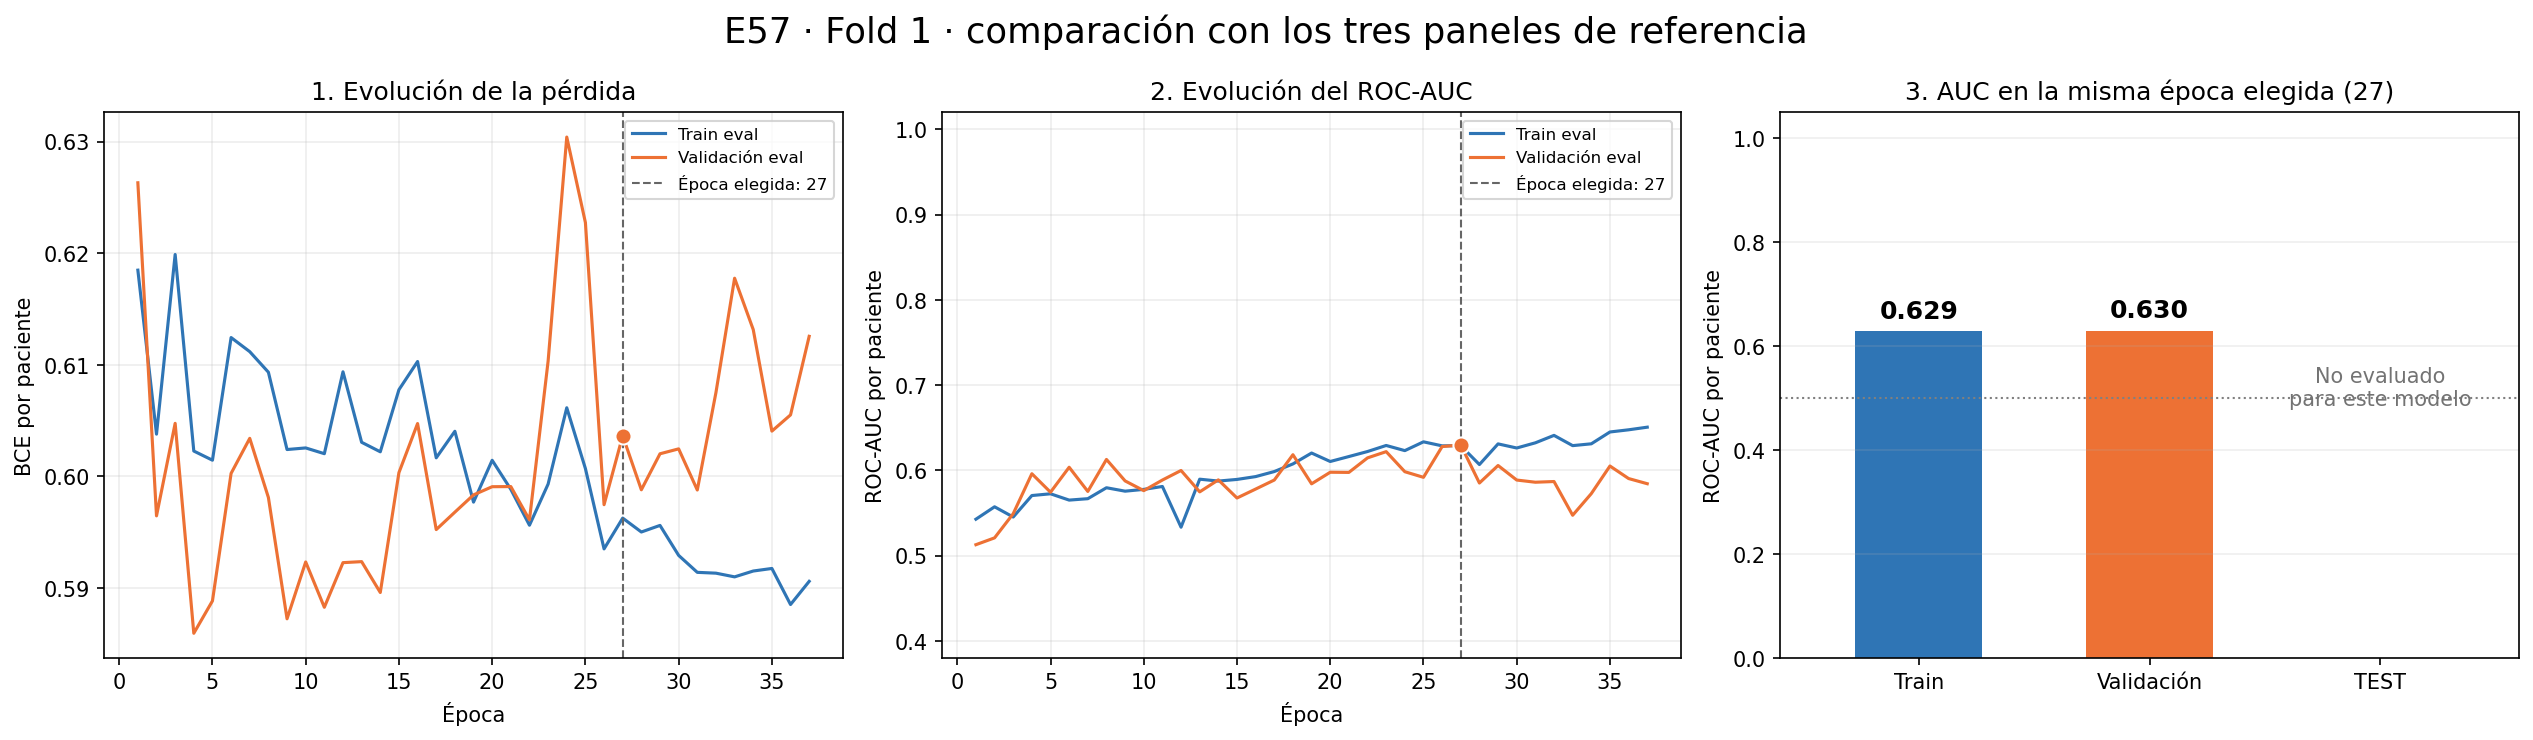

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_1_TRES_GRAFICAS.png')))

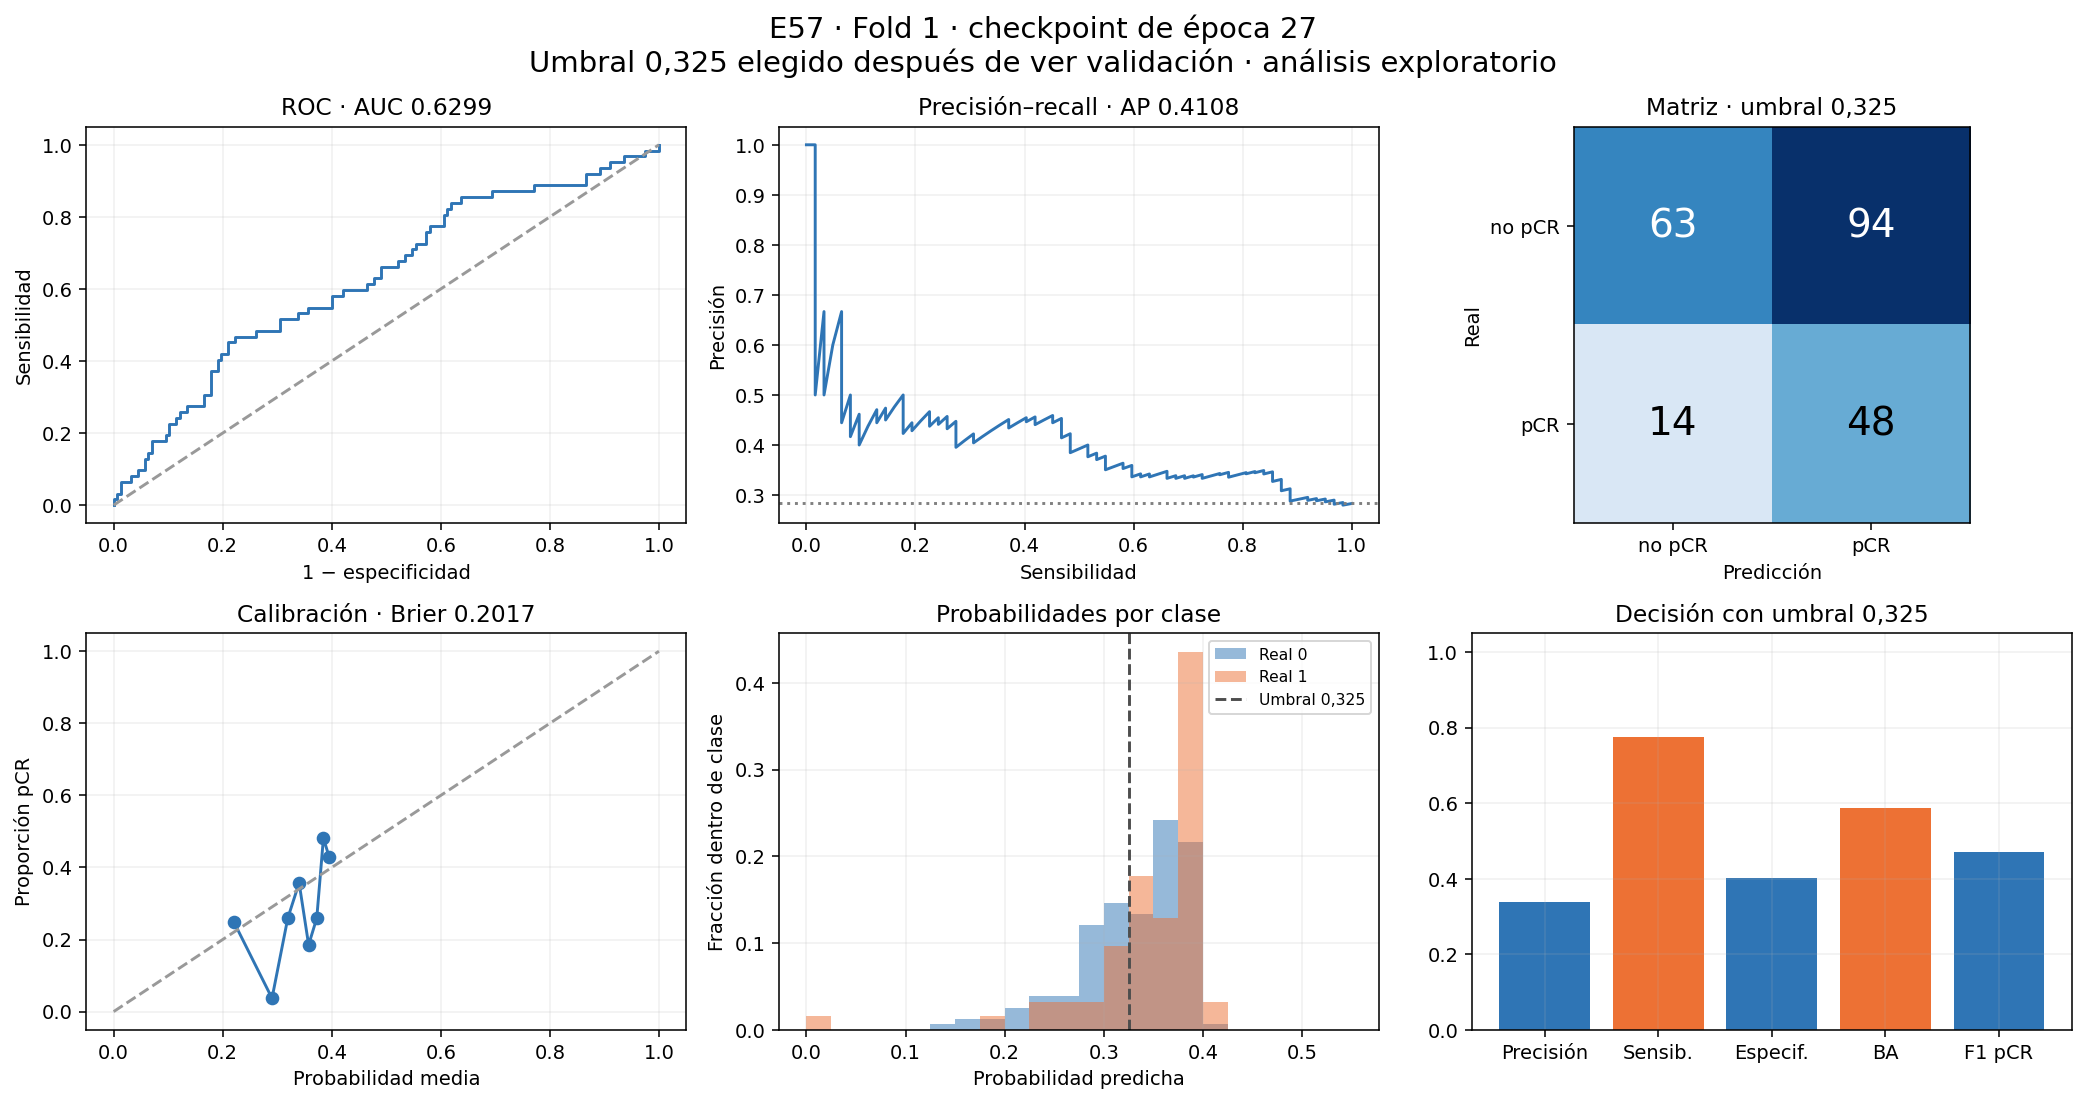

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_1_RESULTADOS.png')))

## Fold 2 · 20 épocas · checkpoint de época 10

### Todas las épocas

|   Época |   BCE train online |   BCE train eval |   BCE val eval |   AUC train eval |   AUC val |   AP val |      LR |   Segundos | Elegida   |
|--------:|-------------------:|-----------------:|---------------:|-----------------:|----------:|---------:|--------:|-----------:|:----------|
|       1 |            0.63061 |          0.61441 |        0.58432 |          0.51134 |   0.57838 |  0.31474 | 0.001   |    96.6154 |           |
|       2 |            0.63633 |          0.63345 |        0.6217  |          0.50196 |   0.50921 |  0.30237 | 0.001   |    94.7917 |           |
|       3 |            0.6288  |          0.62921 |        0.5651  |          0.51492 |   0.55974 |  0.27773 | 0.001   |    95.6487 |           |
|       4 |            0.61507 |          0.61449 |        0.57101 |          0.53296 |   0.62922 |  0.33921 | 0.001   |    97.7831 |           |
|       5 |            0.62313 |          0.61046 |        0.58471 |          0.53743 |   0.52932 |  0.28509 | 0.001   |   100.683  |           |
|       6 |            0.61898 |          0.61068 |        0.5695  |          0.54473 |   0.61449 |  0.35489 | 0.001   |   101.256  |           |
|       7 |            0.62157 |          0.64982 |        0.55642 |          0.52216 |   0.6067  |  0.4027  | 0.001   |   101.783  |           |
|       8 |            0.61731 |          0.61419 |        0.58512 |          0.51149 |   0.56343 |  0.34517 | 0.001   |   101.079  |           |
|       9 |            0.61339 |          0.61786 |        0.55784 |          0.5421  |   0.64249 |  0.38825 | 0.0005  |   101.583  |           |
|      10 |            0.62521 |          0.61445 |        0.57207 |          0.51888 |   0.66881 |  0.4006  | 0.0005  |   102.127  | Sí        |
|      11 |            0.61526 |          0.61698 |        0.56188 |          0.53015 |   0.63091 |  0.41167 | 0.0005  |   101.818  |           |
|      12 |            0.6112  |          0.61511 |        0.56404 |          0.53894 |   0.62596 |  0.39707 | 0.0005  |   101.957  |           |
|      13 |            0.61734 |          0.61308 |        0.57034 |          0.54083 |   0.62849 |  0.38244 | 0.0005  |   103.949  |           |
|      14 |            0.61676 |          0.60958 |        0.57317 |          0.55832 |   0.5869  |  0.35456 | 0.0005  |   104.692  |           |
|      15 |            0.61588 |          0.61236 |        0.59143 |          0.5455  |   0.44668 |  0.23675 | 0.00025 |   103.265  |           |
|      16 |            0.61468 |          0.60862 |        0.57811 |          0.56421 |   0.56701 |  0.33223 | 0.00025 |   101.475  |           |
|      17 |            0.61864 |          0.60894 |        0.58364 |          0.56533 |   0.54879 |  0.33478 | 0.00025 |   102.044  |           |
|      18 |            0.61461 |          0.61032 |        0.58896 |          0.52616 |   0.43436 |  0.23433 | 0.00025 |   101.446  |           |
|      19 |            0.61329 |          0.60762 |        0.5828  |          0.5791  |   0.53827 |  0.28505 | 0.00012 |   101.679  |           |
|      20 |            0.61129 |          0.6075  |        0.57972 |          0.57245 |   0.56785 |  0.29571 | 0.00012 |   102.214  |           |

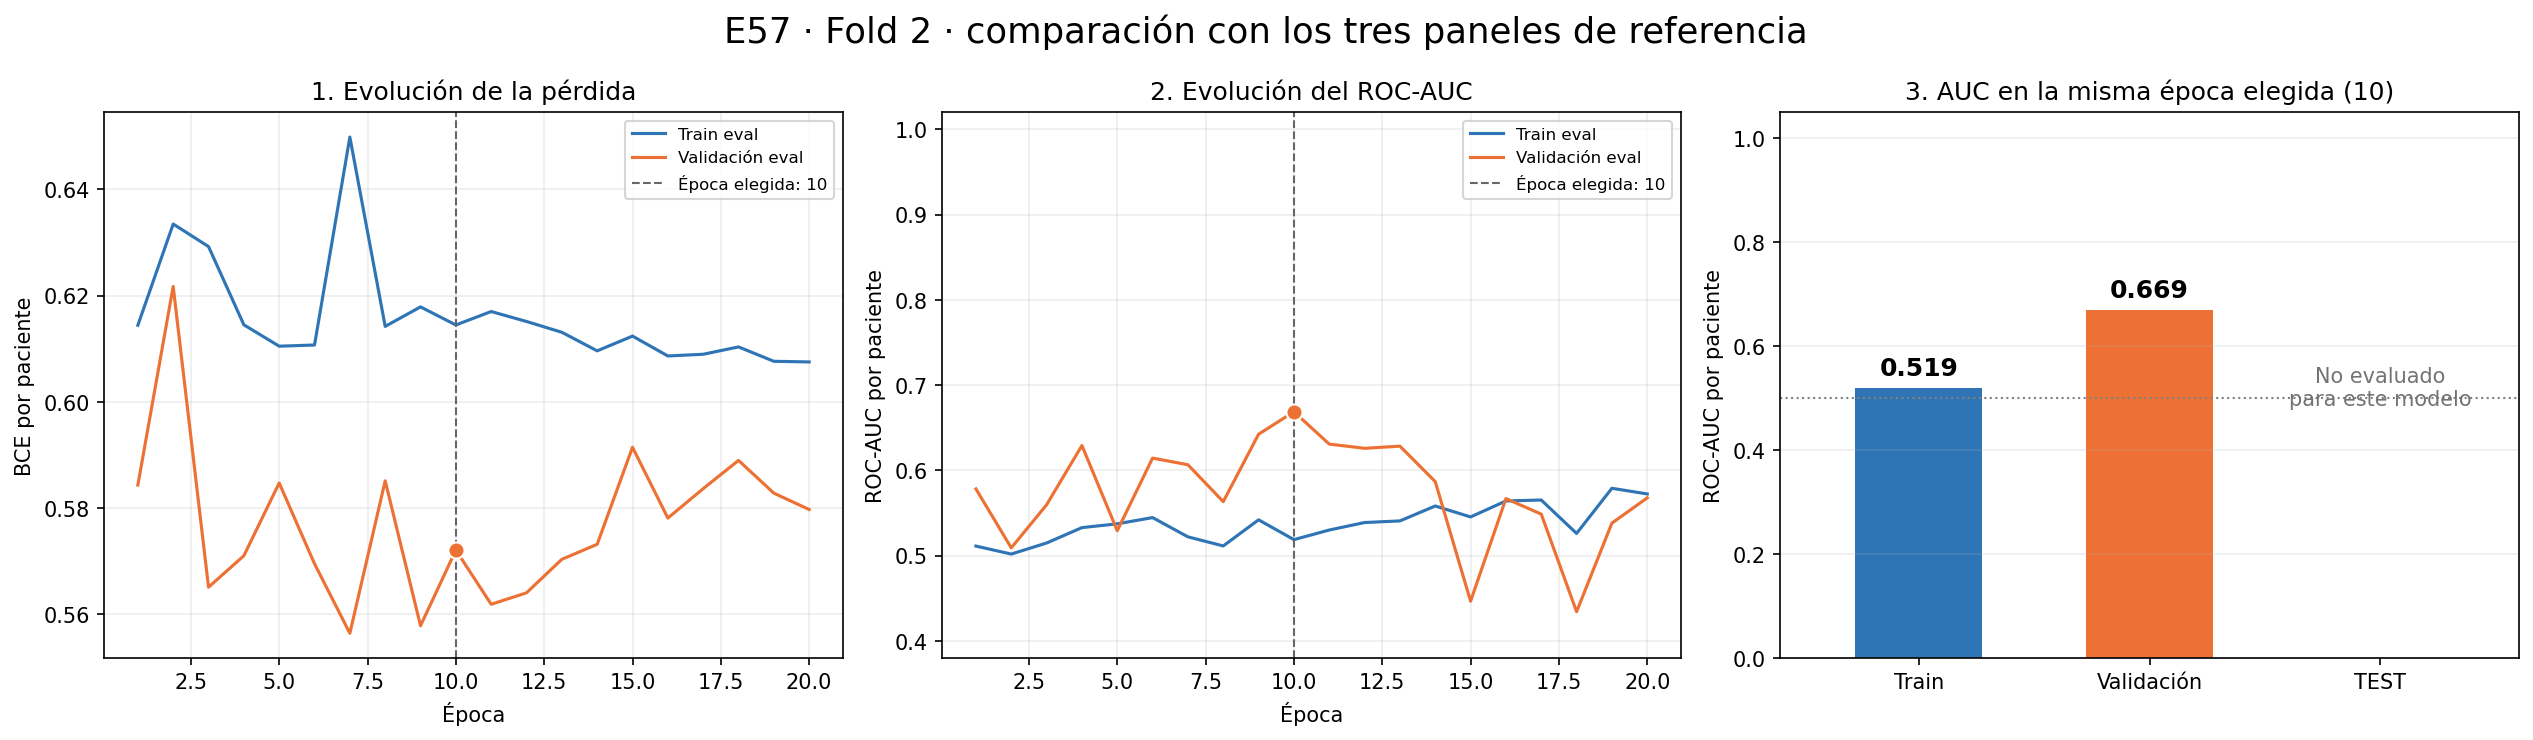

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_2_TRES_GRAFICAS.png')))

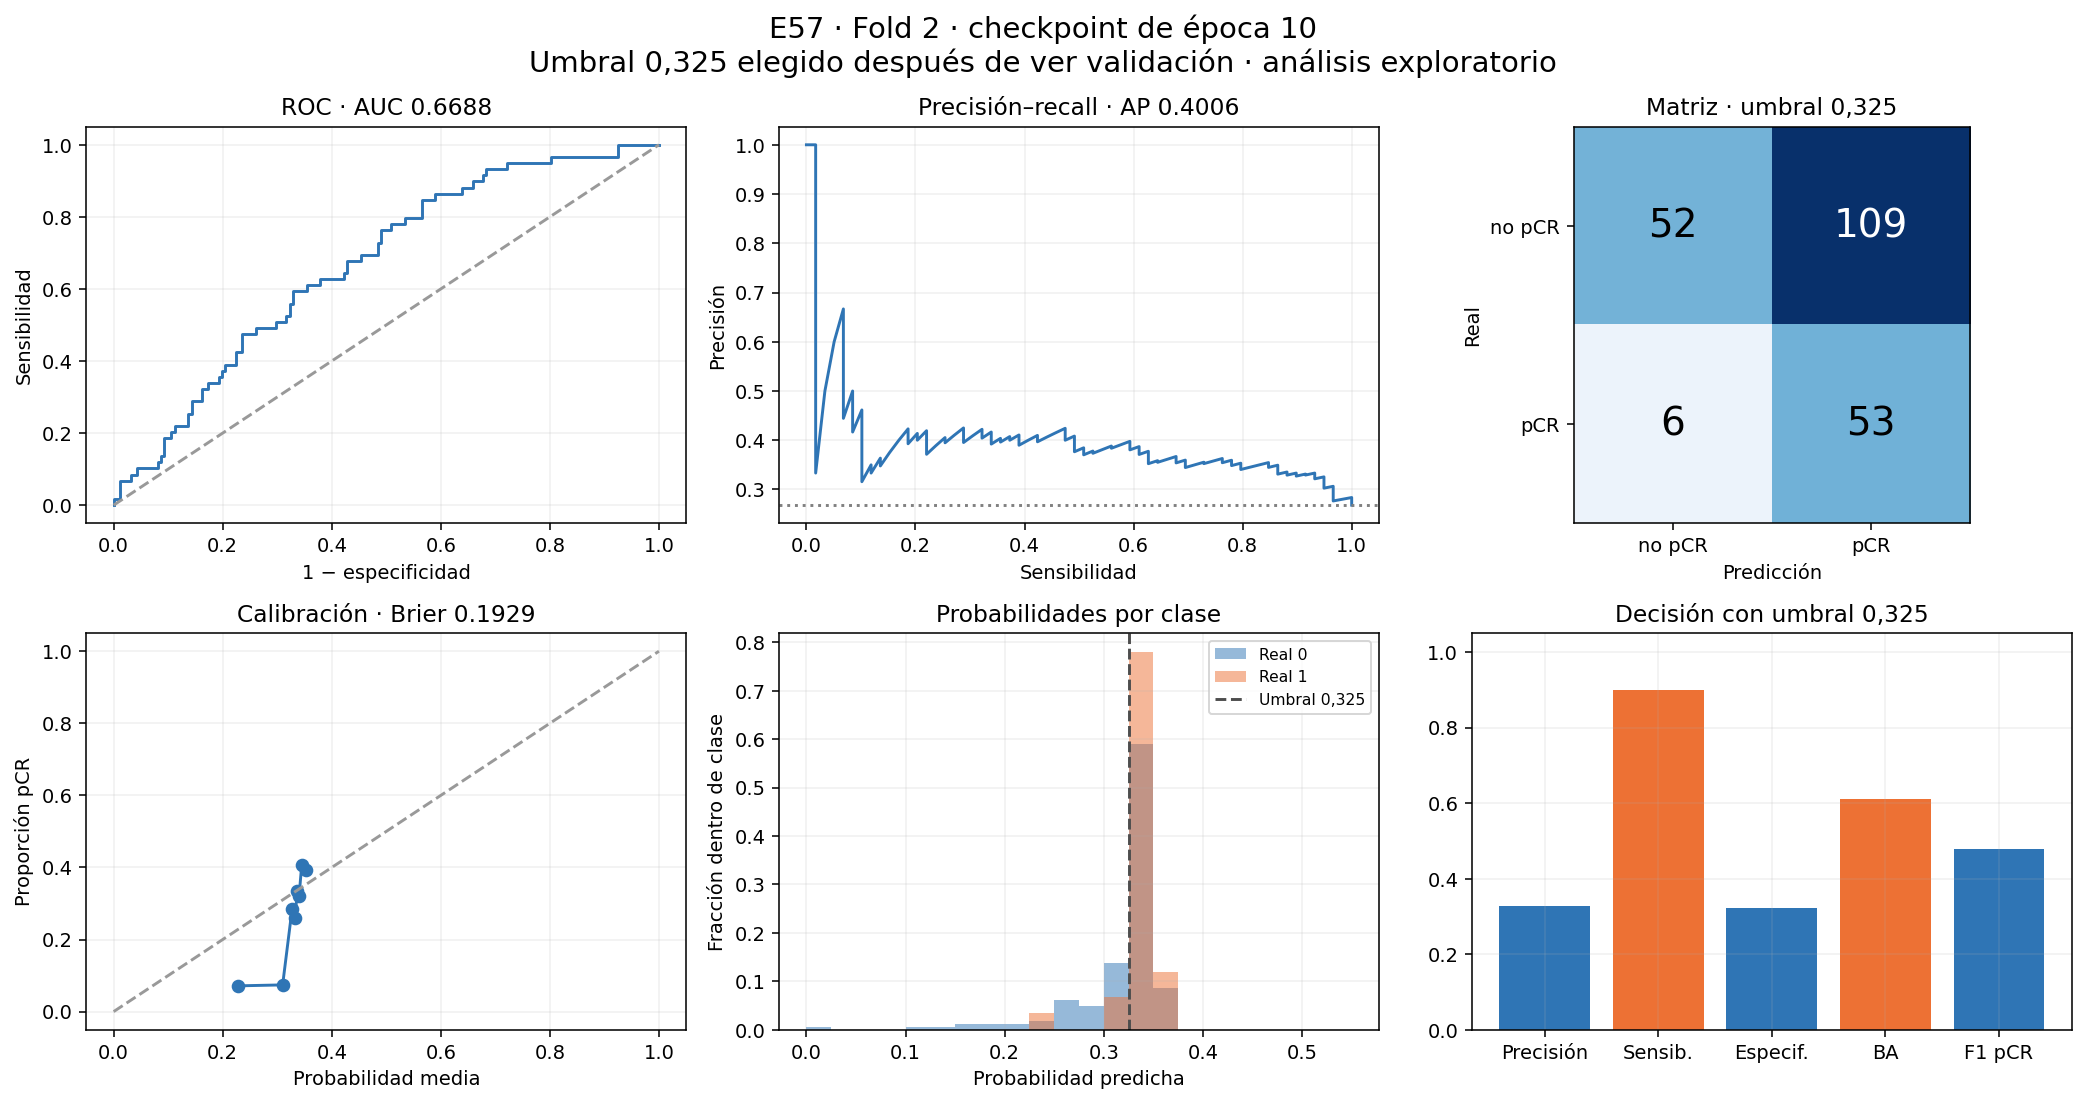

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_2_RESULTADOS.png')))

## Fold 3 · 12 épocas · checkpoint de época 2

### Todas las épocas

|   Época |   BCE train online |   BCE train eval |   BCE val eval |   AUC train eval |   AUC val |   AP val |      LR |   Segundos | Elegida   |
|--------:|-------------------:|-----------------:|---------------:|-----------------:|----------:|---------:|--------:|-----------:|:----------|
|       1 |            0.61698 |          0.59719 |        0.64118 |          0.52481 |   0.53857 |  0.40808 | 0.001   |    100.348 |           |
|       2 |            0.614   |          0.59355 |        0.64718 |          0.54038 |   0.55034 |  0.41611 | 0.001   |    101.869 | Sí        |
|       3 |            0.60616 |          0.5961  |        0.65604 |          0.52036 |   0.49094 |  0.31779 | 0.001   |    102.338 |           |
|       4 |            0.61297 |          0.59533 |        0.66247 |          0.52682 |   0.47706 |  0.33263 | 0.001   |    102.468 |           |
|       5 |            0.60847 |          0.59918 |        0.67993 |          0.52422 |   0.4789  |  0.32447 | 0.001   |    106.254 |           |
|       6 |            0.60039 |          0.59623 |        0.67045 |          0.54574 |   0.48294 |  0.35122 | 0.001   |    104.895 |           |
|       7 |            0.59828 |          0.59468 |        0.66293 |          0.54045 |   0.45756 |  0.31892 | 0.0005  |    102.798 |           |
|       8 |            0.59944 |          0.59206 |        0.6673  |          0.5498  |   0.40616 |  0.28329 | 0.0005  |    101.982 |           |
|       9 |            0.60852 |          0.59422 |        0.6492  |          0.53536 |   0.48589 |  0.32897 | 0.0005  |    101.653 |           |
|      10 |            0.60535 |          0.58959 |        0.65227 |          0.56389 |   0.45471 |  0.31218 | 0.0005  |    101.922 |           |
|      11 |            0.59598 |          0.59042 |        0.66085 |          0.5721  |   0.44101 |  0.30282 | 0.00025 |    102.264 |           |
|      12 |            0.60521 |          0.59016 |        0.65272 |          0.58241 |   0.44901 |  0.31179 | 0.00025 |    101.857 |           |

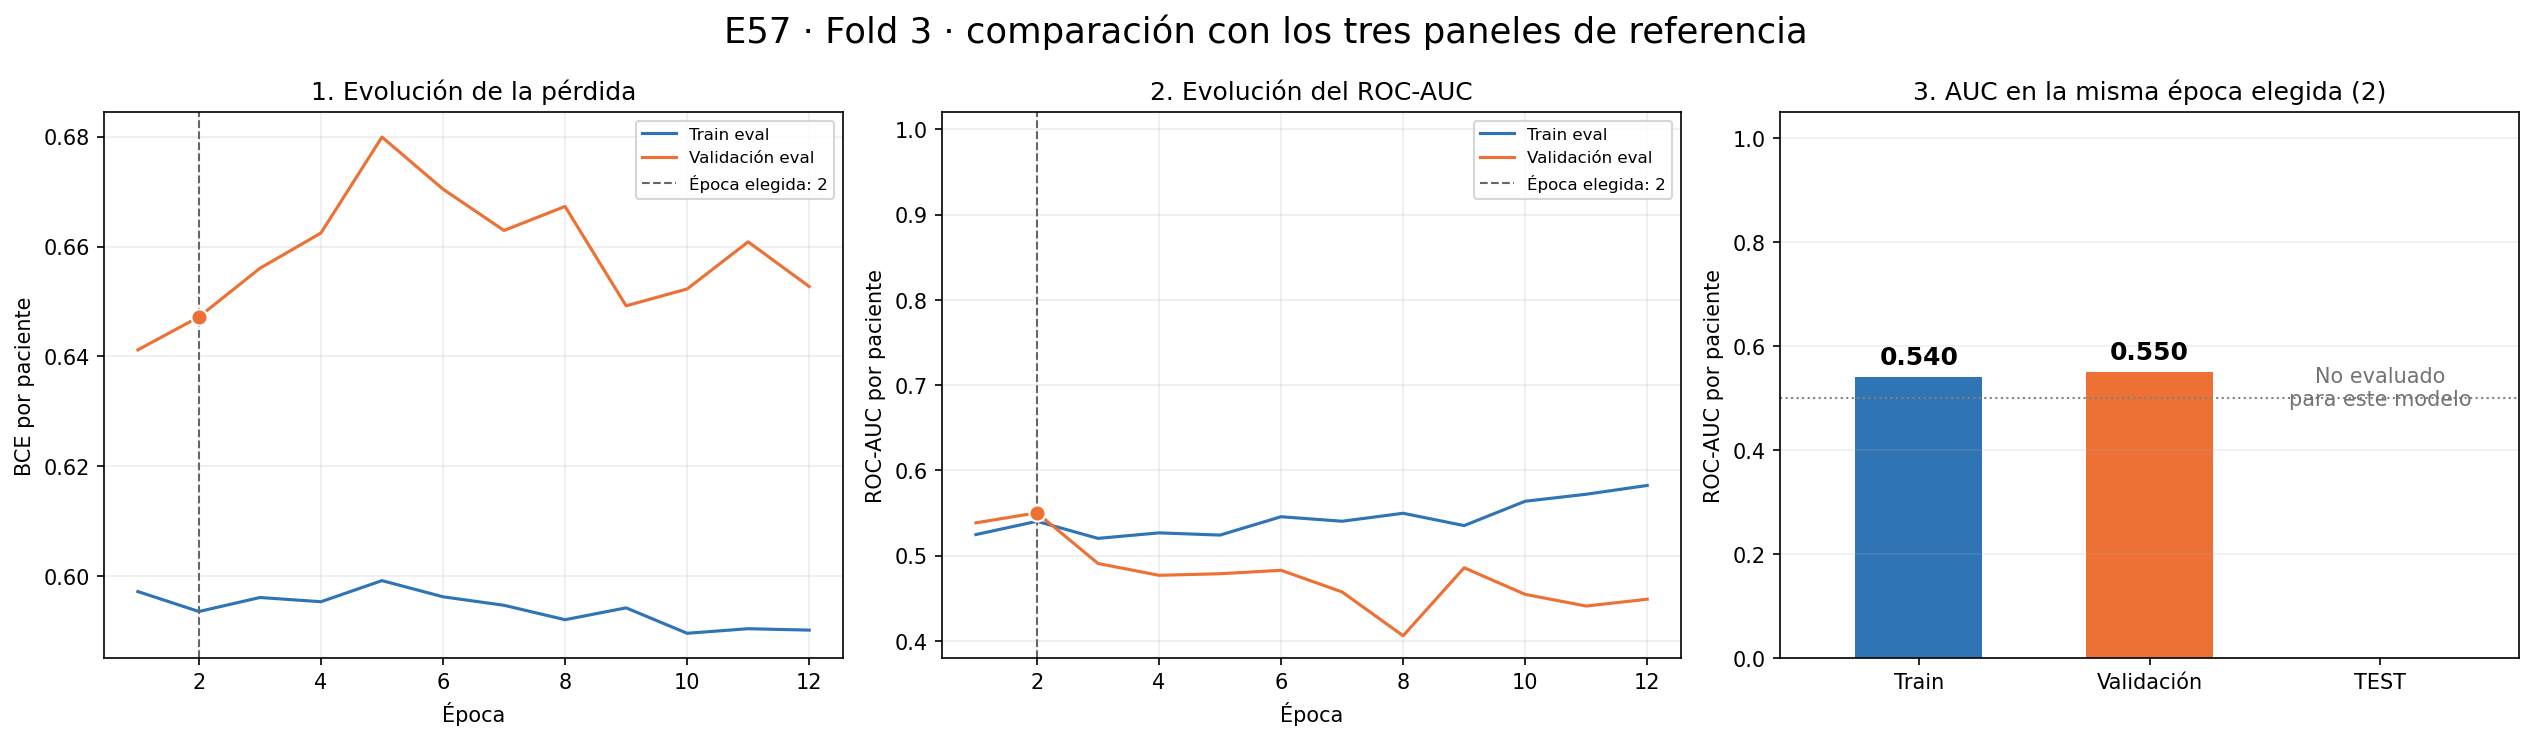

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_3_TRES_GRAFICAS.png')))

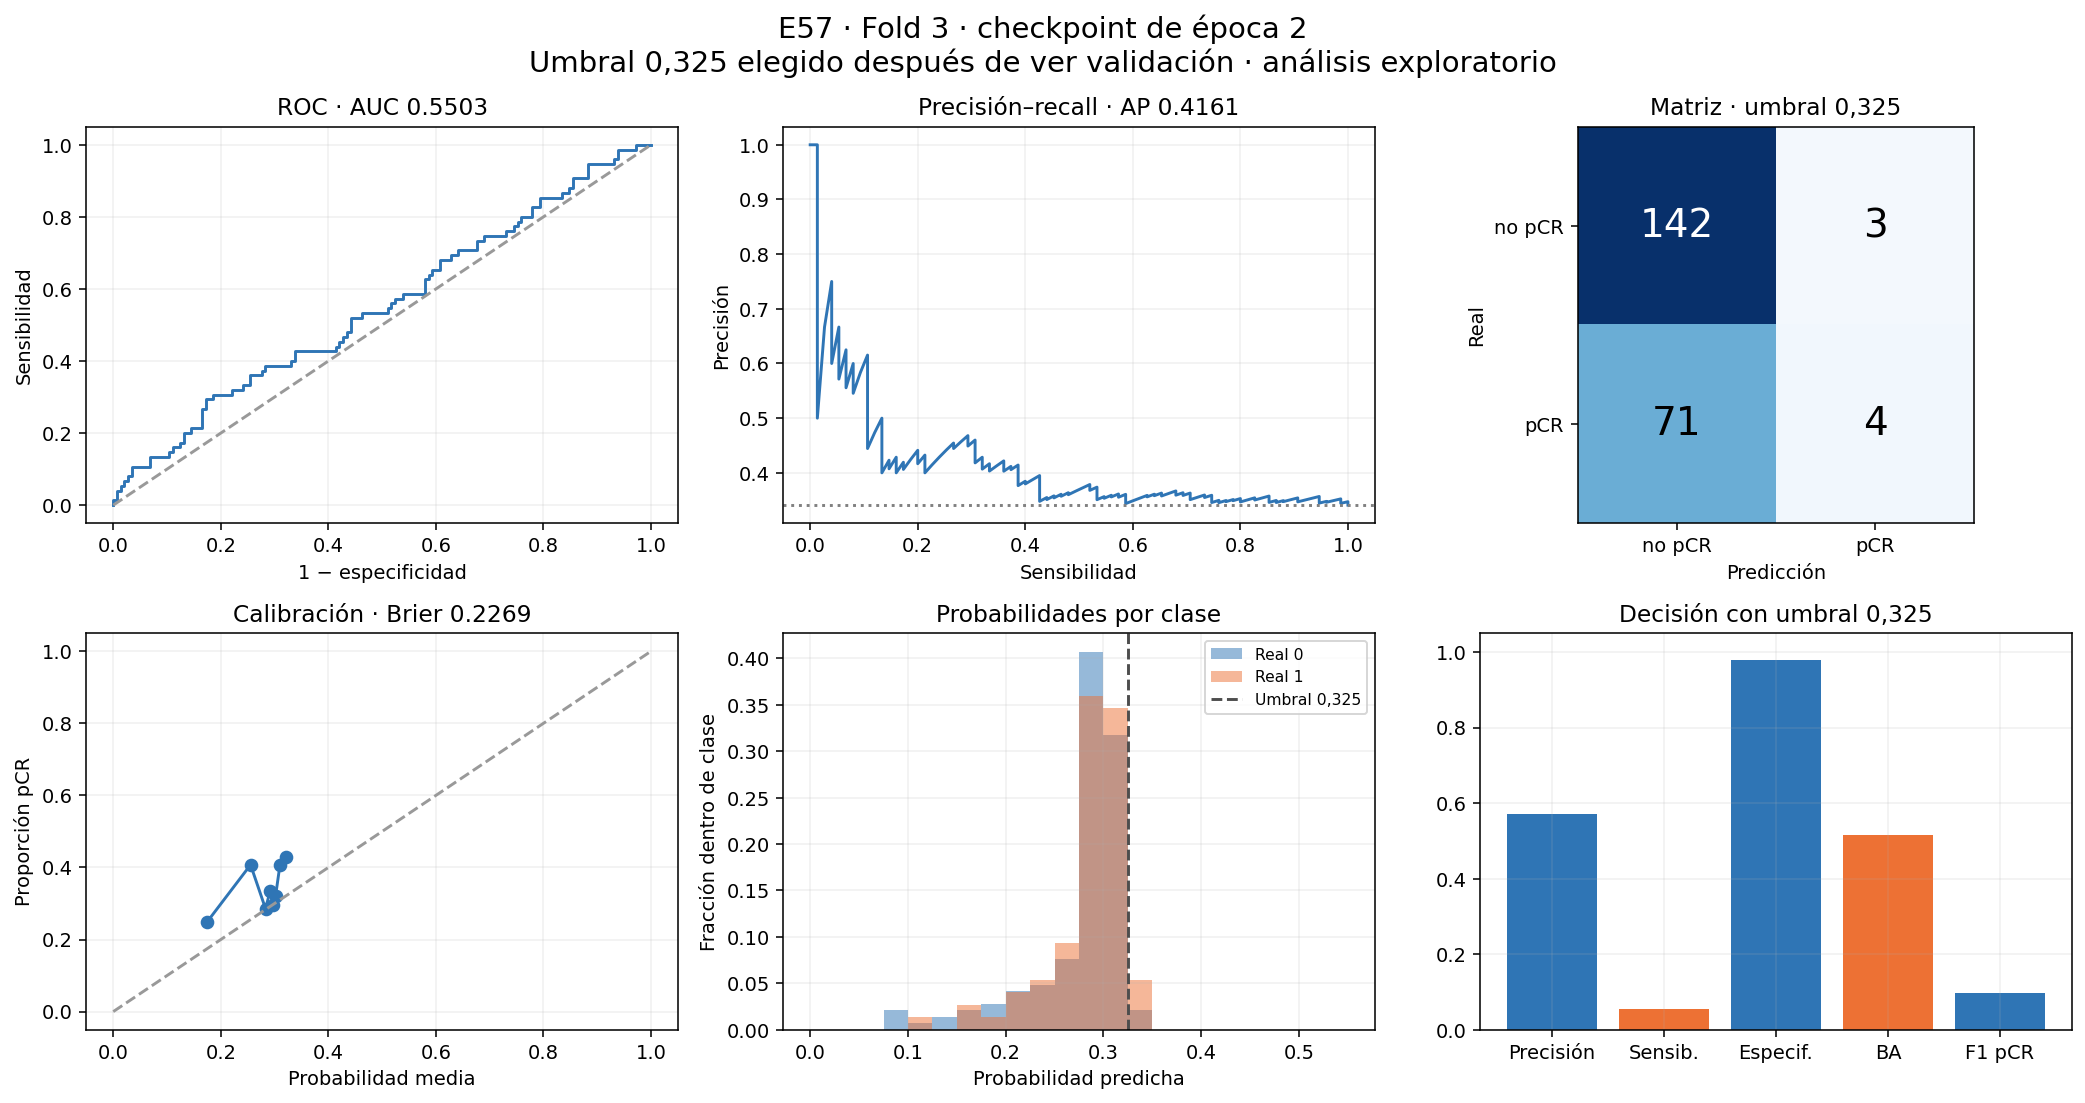

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_3_RESULTADOS.png')))

## Fold 4 · 15 épocas · checkpoint de época 5

### Todas las épocas

|   Época |   BCE train online |   BCE train eval |   BCE val eval |   AUC train eval |   AUC val |   AP val |      LR |   Segundos | Elegida   |
|--------:|-------------------:|-----------------:|---------------:|-----------------:|----------:|---------:|--------:|-----------:|:----------|
|       1 |            0.63087 |          0.61034 |        0.61028 |          0.50243 |   0.47349 |  0.27869 | 0.001   |    99.7836 |           |
|       2 |            0.62818 |          0.61225 |        0.60573 |          0.49651 |   0.50514 |  0.27937 | 0.001   |   100.73   |           |
|       3 |            0.61455 |          0.60877 |        0.60517 |          0.51898 |   0.53061 |  0.3251  | 0.001   |   101.044  |           |
|       4 |            0.61856 |          0.61219 |        0.59883 |          0.5131  |   0.49363 |  0.30659 | 0.001   |   100.769  |           |
|       5 |            0.62106 |          0.61469 |        0.60142 |          0.48886 |   0.59266 |  0.39774 | 0.001   |   102.828  | Sí        |
|       6 |            0.61126 |          0.61208 |        0.59708 |          0.52015 |   0.50925 |  0.31213 | 0.001   |   101.419  |           |
|       7 |            0.61666 |          0.60747 |        0.59939 |          0.53031 |   0.51274 |  0.33192 | 0.001   |   101.49   |           |
|       8 |            0.62229 |          0.60802 |        0.59947 |          0.52878 |   0.51315 |  0.33661 | 0.001   |   101.747  |           |
|       9 |            0.61761 |          0.60746 |        0.59807 |          0.5202  |   0.48192 |  0.29691 | 0.001   |   102.786  |           |
|      10 |            0.61186 |          0.61105 |        0.60452 |          0.52671 |   0.49003 |  0.29178 | 0.0005  |   101.458  |           |
|      11 |            0.61674 |          0.61042 |        0.60409 |          0.5547  |   0.50966 |  0.30849 | 0.0005  |   102.582  |           |
|      12 |            0.61488 |          0.60581 |        0.60043 |          0.55187 |   0.49476 |  0.30756 | 0.0005  |   102.883  |           |
|      13 |            0.61568 |          0.60521 |        0.60185 |          0.55536 |   0.57746 |  0.34459 | 0.0005  |   119.778  |           |
|      14 |            0.61124 |          0.60339 |        0.59708 |          0.55719 |   0.57828 |  0.36029 | 0.00025 |   102.621  |           |
|      15 |            0.60839 |          0.60436 |        0.60151 |          0.56827 |   0.54736 |  0.33081 | 0.00025 |   100.704  |           |

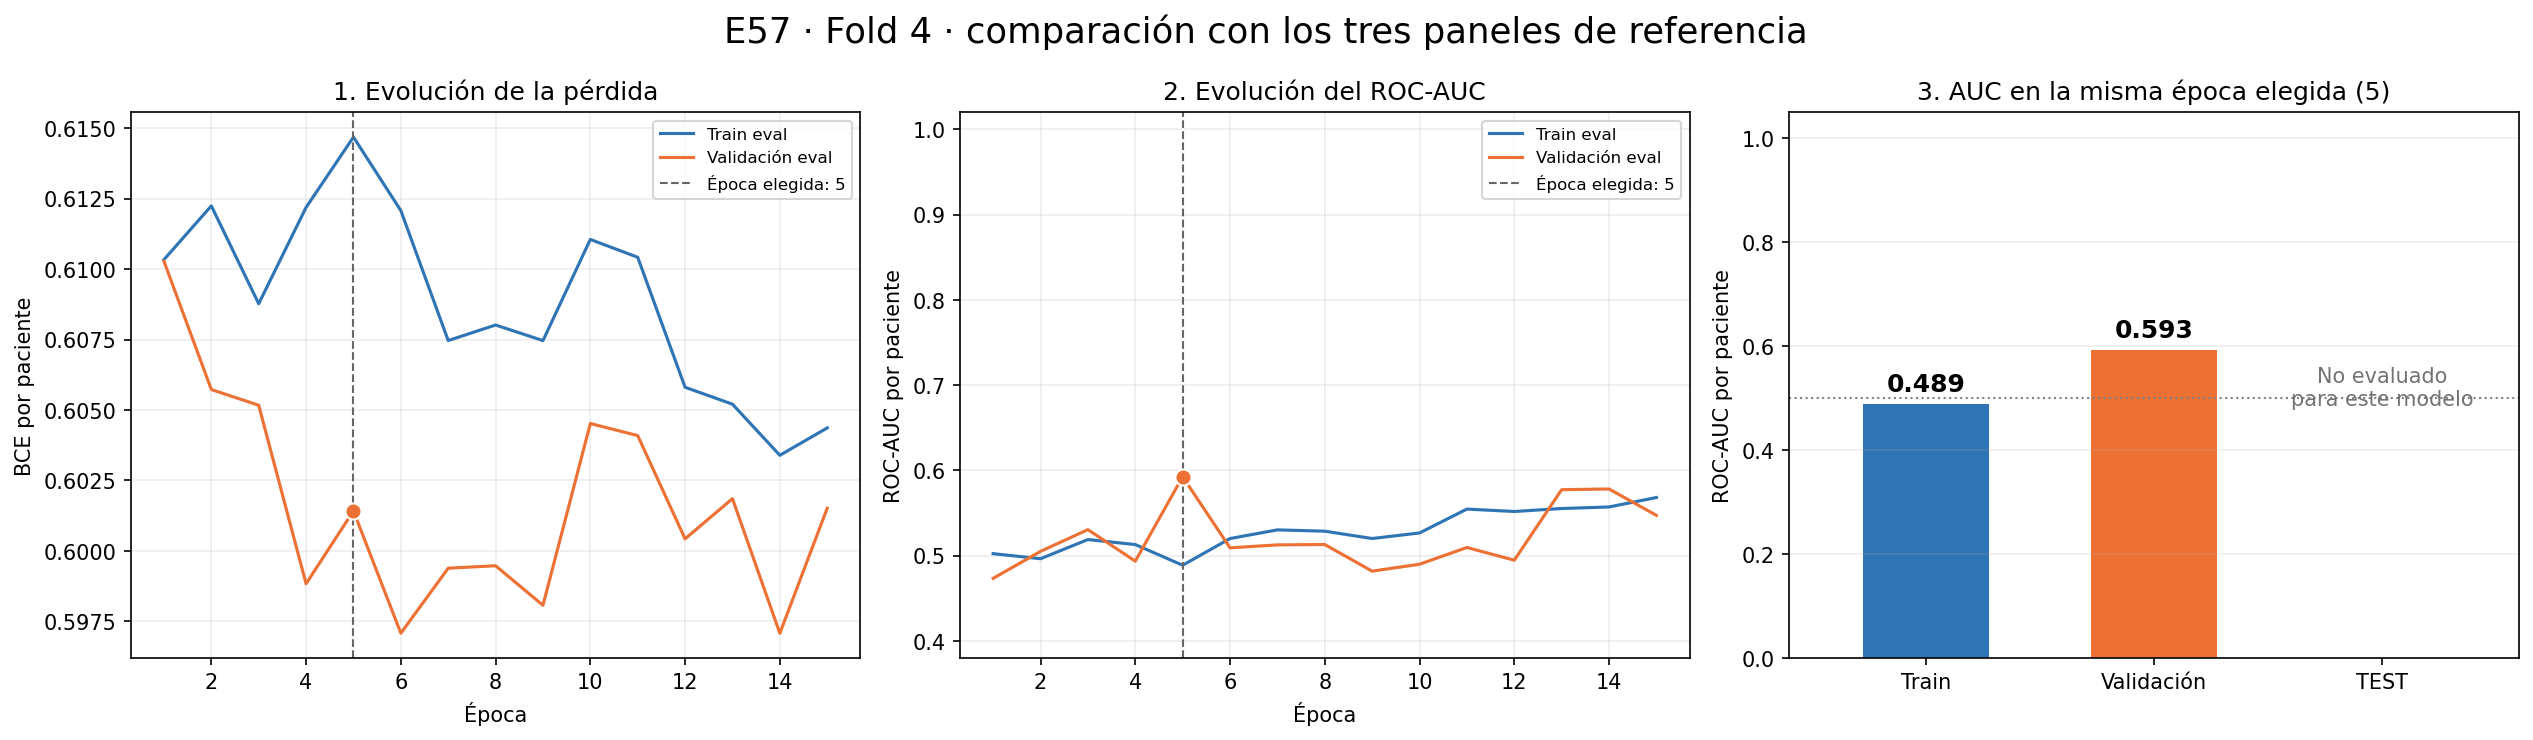

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_4_TRES_GRAFICAS.png')))

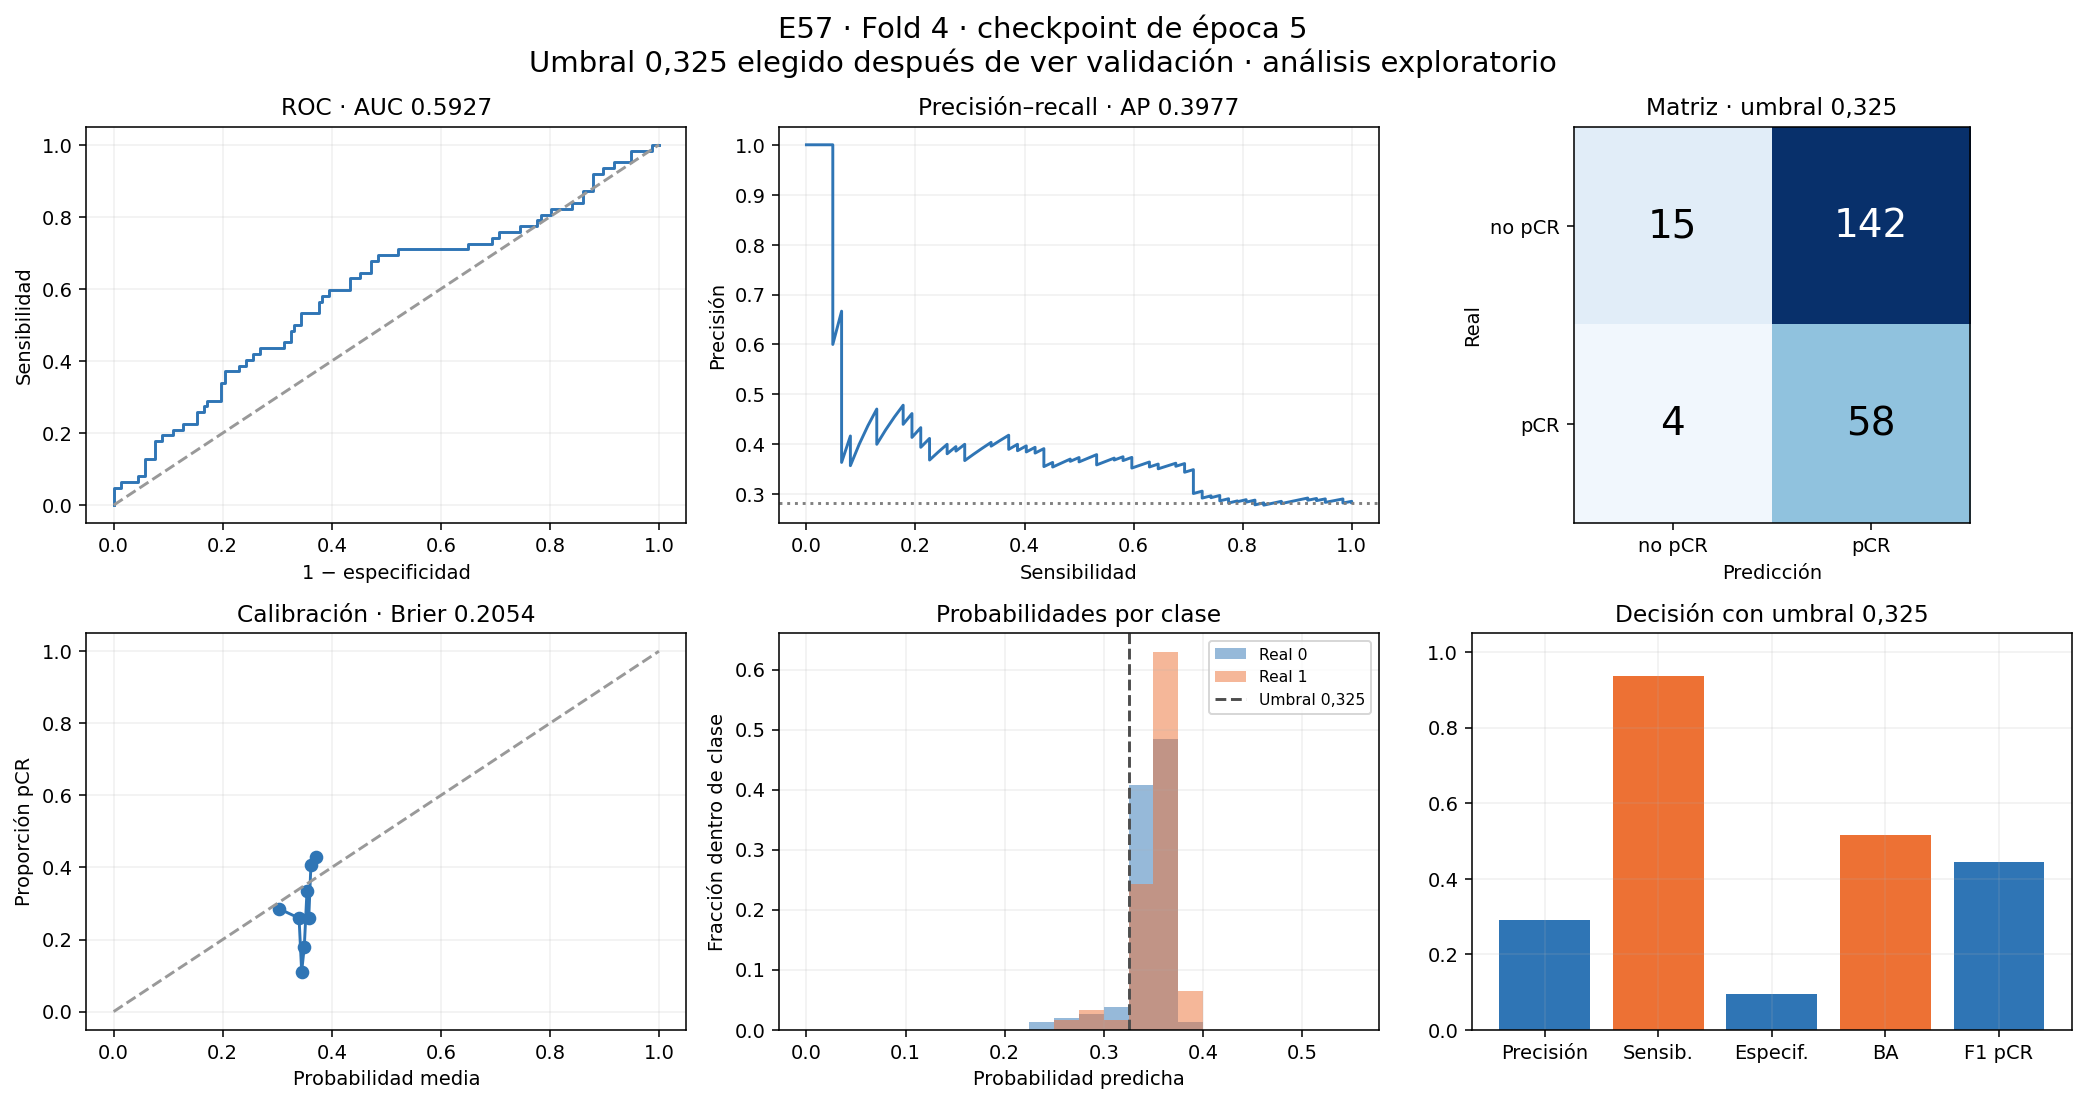

In [1]:
from pathlib import Path
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'AGENTS.md').is_file())
display(Image(filename=str(root/'E57/GRAFICAS/FOLD_4_RESULTADOS.png')))

## Cómo leer estos resultados

AUC describe ordenación y no depende del umbral. La matriz depende del corte elegido. Los cinco folds reúnen 1.097 pacientes: con 0,325 hay TN381, FP394, FN123 y TP199. Esto corresponde a sensibilidad 61,8 %, especificidad 49,2 % y precisión pCR 33,6 %. Las matrices tienen más predicciones positivas, pero aún hay muchos errores. La arquitectura se mantiene como referencia de trabajo; su desempeño final necesita selección interna y evaluación separada.

Uso educativo, sin validez clínica.